
# EmotionLab
## Análisis de datos y Machine Learning

**Proyecto Capstone — Ingeniería en Informática**

**Integrantes:**
- Lorena Calfin
- Martín Carrere
- Emily Gonzales

**Profesor guía:** Cristian Molina

---

## Objetivo general

Desarrollar un módulo inteligente para analizar las
respuestas emocionales autodeclaradas de estudiantes
durante presentaciones orales, identificar patrones
mediante técnicas de Machine Learning y proporcionar
una clasificación exploratoria de sus niveles de
tensión percibida.

## Descripción

EmotionLab recopila respuestas emocionales autodeclaradas mediante tres formularios aplicados durante una experiencia de presentación oral: antes de presentar, después de la modalidad fácil y después de la modalidad difícil.

El módulo de análisis utilizará la información de los tres formularios para desarrollar un análisis global del estudiante, identificando patrones mediante técnicas de Machine Learning y proporcionando una clasificación exploratoria de su nivel general de tensión percibida.

Adicionalmente, se analizará la evolución de las respuestas entre etapas, permitiendo visualizar los cambios en el nerviosismo y el estado emocional durante la experiencia.

## Alcance del modelo

Los resultados representarán patrones y niveles
exploratorios de tensión emocional autodeclarada.

No se utilizarán como diagnóstico psicológico ni como
medición clínica de estrés.



# Etapa 1: Carga y revisión inicial del dataset

## Objetivo

En esta etapa trabajaremos con el dataset híbrido que
construimos previamente para el proyecto EmotionLab.

El dataset está compuesto por 600 registros:

- 27 registros originales obtenidos de estudiantes.
- 573 registros sintéticos generados a partir de los datos reales.

Antes de utilizar técnicas de Machine Learning, debemos
comprobar que los datos se carguen correctamente, que las
variables estén disponibles y que podamos distinguir los
registros reales de los sintéticos.

Para esto utilizaremos Python, pandas y Google Colab.


In [33]:

# Bibliotecas necesarias para usos muy generales o usos únicos
import numpy as np
import pandas as pd
import io
from google.colab import files
import matplotlib.pyplot as plt

# estas bibliotecas utilizaremos para visualizar las versiones de cada biblioteca a utilizar,
# si no las tenemos seteadas desde un inicio, a la hora de hacer el importe a AWS, AWS instalará las versiones mas recientes de estas bibliotecas
# lo cual puede generar conflictos.
import sys
import pandas as pd
import scipy
import sklearn
import matplotlib
import seaborn as sns
import joblib



## 1.1 Configuración general del proyecto

En esta sección definiremos los parámetros que
utilizaremos durante el desarrollo.

Establecer una semilla aleatoria permitirá reproducir
los experimentos que involucren procesos aleatorios.

También definiremos la cantidad esperada de registros
y las variables que identifican cada formulario.

El análisis de las respuestas observadas se realizará
sobre los participantes reales. Los registros sintéticos
se conservarán para experimentación y pruebas técnicas,
sin considerarlos nuevas observaciones independientes.


In [2]:

# Definimos una semilla para que los experimentos
# aleatorios puedan reproducirse.
# La semilla se crea con el número 42 sin algún proposito en especifico, ya que puede ser cualquier número y el resultado será el mismo, mientras el número de la semilla sea el mismo

SEMILLA = 42
np.random.seed(SEMILLA)

# Cantidades esperadas en el dataset.
# Las comprobaremos al cargar el archivo.

REGISTROS_REALES = 27
REGISTROS_SINTETICOS = 573
REGISTROS_TOTALES = 600

# Valores permitidos por los formularios.

ESCALA_MINIMA = 1
ESCALA_MAXIMA = 9

# Identificamos las variables de cada etapa.

variables_iniciales = [
    "estado_pre",
    "nerviosismo_pre",
    "preocupacion_pre",
    "preparacion_pre"
]

variables_facil = [
    "estado_facil",
    "nerviosismo_facil",
    "satisfaccion_facil",
    "alivio_facil"
]

variables_dificil = [
    "estado_dificil",
    "nerviosismo_dificil",
    "satisfaccion_dificil",
    "alivio_dificil"
]

# Unimos las variables para facilitar
# su utilización en los análisis posteriores.

variables_cuestionario = (
    variables_iniciales
    + variables_facil
    + variables_dificil
)

print("Semilla aleatoria:", SEMILLA)
print("Registros esperados:", REGISTROS_TOTALES)
print("Variables del cuestionario:", len(variables_cuestionario))
print("Escala:", ESCALA_MINIMA, "a", ESCALA_MAXIMA)


Semilla aleatoria: 42
Registros esperados: 600
Variables del cuestionario: 12
Escala: 1 a 9



## 1.2 Verificación de versiones

Antes de comenzar el procesamiento, registraremos
las versiones de Python y de las principales
bibliotecas utilizadas.

Esto permitirá documentar el entorno de desarrollo
y facilitará la reproducción de los experimentos.

También será útil al trasladar los modelos entrenados
desde Google Colab al backend de AWS, donde necesitaremos
mantener un entorno compatible.


In [31]:

# Consultamos las versiones de las herramientas
# principales del proyecto.

versiones = {
    "Python": sys.version.split()[0],
    "pandas": pd.__version__,
    "NumPy": np.__version__,
    "SciPy": scipy.__version__,
    "Matplotlib": matplotlib.__version__,
    "Seaborn": sns.__version__,
    "scikit-learn": sklearn.__version__,
    "joblib": joblib.__version__,
    "matplotlib": matplotlib.__version__
}

# Organizamos las versiones en una tabla
# para facilitar su lectura.

tabla_versiones = pd.DataFrame(
    versiones.items(),
    columns=["Herramienta", "Versión instalada"]
)

print("Versiones del entorno de desarrollo:")
display(tabla_versiones)


Versiones del entorno de desarrollo:


,Herramienta,Versión instalada
0,Python,3.13.18
1,pandas,2.2.3
2,NumPy,2.4.6
3,SciPy,1.16.3
4,Matplotlib,3.10.0
5,Seaborn,0.13.2
6,scikit-learn,1.6.1
7,joblib,1.6.0
8,matplotlib,3.10.0



## Conclusión de la Etapa 1

Se configuró el entorno de desarrollo para el módulo
de análisis y Machine Learning de EmotionLab.

Se importaron las bibliotecas necesarias para el
procesamiento de datos, análisis estadístico,
visualización, entrenamiento no supervisado y
evaluación de agrupaciones.

También se establecieron los parámetros generales
del proyecto y se identificaron las doce variables
correspondientes a los tres formularios.

Finalmente, se incorporó un procedimiento para
registrar las versiones de las herramientas utilizadas.

Con esta configuración, el entorno queda preparado
para cargar y validar el dataset de EmotionLab.



# Etapa 2: Carga y validación del dataset


## Objetivo

Cargar el dataset híbrido construido previamente
para EmotionLab y comprobar que su estructura
sea adecuada para las siguientes etapas del proyecto.

El conjunto de datos contiene 600 registros:

- 27 registros originales de estudiantes.
- 573 registros sintéticos generados experimentalmente.

Durante esta etapa verificaremos la integridad de
la información, la disponibilidad de las variables
y la procedencia de los registros.

## Procedimiento

1. Cargar el archivo CSV del dataset.
2. Revisar su estructura y tipos de datos.
3. Comprobar la cantidad y procedencia de registros.
4. Examinar la disponibilidad de respuestas.
5. Validar que las respuestas respeten la escala
   definida en los formularios.
6. Separar los datos reales de los sintéticos.

## Consideraciones

No eliminaremos ni modificaremos respuestas originales.

Los valores ausentes se conservarán para estudiar
su tratamiento durante el preprocesamiento.

El dataset sintético se utilizará principalmente
para experimentación y pruebas técnicas, mientras
que las conclusiones sobre estudiantes se basarán
en los registros reales disponibles.


##**2.1 Carga del dataset hibrido**

Hacemos carga del dataset hibrido creado por nosotros

In [4]:

# Cargamos el dataset generado anteriormente.
print("Selecciona el dataset de EmotionLab.")

archivo_subido = files.upload()

# Comprobamos que se haya seleccionado un solo archivo.
if len(archivo_subido) != 1:
    raise ValueError("Debes cargar solamente un archivo.")

nombre_archivo = list(archivo_subido.keys())[0]
contenido = archivo_subido[nombre_archivo]

# Leemos el dataset según su formato.
if nombre_archivo.lower().endswith(".csv"):
    dataset = pd.read_csv(io.BytesIO(contenido), encoding="utf-8-sig")
elif nombre_archivo.lower().endswith(".xlsx"):
    dataset = pd.read_excel(io.BytesIO(contenido))
else:
    raise ValueError("El archivo debe ser CSV o XLSX.")

print("Archivo cargado:", nombre_archivo)
print("Dimensiones:", dataset.shape)


Selecciona el dataset de EmotionLab.


Saving EmotionLab_Dataset_Hibrido_600.csv to EmotionLab_Dataset_Hibrido_600.csv
Archivo cargado: EmotionLab_Dataset_Hibrido_600.csv
Dimensiones: (600, 21)



## 2.2 Revisión inicial de la estructura

Antes de procesar los datos, revisaremos cómo están
organizados dentro del archivo.

Para ello utilizaremos las funciones de pandas:

- shape: identifica la cantidad de filas y columnas.
- head: muestra una vista preliminar del dataset.
- info: presenta los tipos de datos y valores presentes.
- dtypes: permite revisar el tipo de cada variable.

Esta revisión es importante para detectar posibles
problemas de lectura o inconsistencias en los datos.

También permitirá comprobar que las respuestas de
los formularios se encuentren organizadas correctamente.


In [5]:

# Revisamos el tamaño del dataset.
print("Registros:", dataset.shape[0])
print("Columnas:", dataset.shape[1])

# Visualizamos los primeros cinco registros.
print("\nPrimeras filas:")
display(dataset.head())

# Consultamos los tipos de datos de las columnas.
print("\nTipos de datos:")
display(dataset.dtypes.to_frame(name="Tipo de dato"))

# Revisamos la estructura general y los valores no nulos.
print("\nInformación general:")
dataset.info()


Registros: 600
Columnas: 21

Primeras filas:


,id_estudiante,tipo_origen,bloque_origen,edad,genero,n_respuestas,integridad,alivio_dificil,alivio_facil,estado_dificil,...,estado_pre,nerviosismo_dificil,nerviosismo_facil,nerviosismo_pre,preocupacion_pre,preparacion_pre,satisfaccion_dificil,satisfaccion_facil,tipo_registro,id_semilla
0,EM_001,nombre,1,17.0,m,12,completo,1.0,3.0,4.0,...,1.0,3.0,4.0,3.0,4.0,3.0,1.0,2.0,real,NaN
1,EM_002,nombre,1,17.0,m,12,completo,5.0,2.0,2.0,...,2.0,3.0,3.0,3.0,1.0,4.0,4.0,1.0,real,NaN
2,EM_003,nombre,1,17.0,m,12,completo,1.0,1.0,4.0,...,1.0,3.0,1.0,1.0,9.0,1.0,2.0,1.0,real,NaN
3,EM_004,nombre,1,18.0,f,12,completo,1.0,1.0,2.0,...,3.0,2.0,1.0,5.0,4.0,3.0,1.0,2.0,real,NaN
4,EM_005,nombre,1,18.0,f,12,completo,3.0,6.0,2.0,...,2.0,3.0,6.0,3.0,1.0,4.0,1.0,7.0,real,NaN



Tipos de datos:


,Tipo de dato
id_estudiante,object
tipo_origen,object
bloque_origen,int64
edad,float64
genero,object
n_respuestas,int64
integridad,object
alivio_dificil,float64
alivio_facil,float64
estado_dificil,float64



Información general:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id_estudiante         600 non-null    object 
 1   tipo_origen           600 non-null    object 
 2   bloque_origen         600 non-null    int64  
 3   edad                  598 non-null    float64
 4   genero                571 non-null    object 
 5   n_respuestas          600 non-null    int64  
 6   integridad            600 non-null    object 
 7   alivio_dificil        349 non-null    float64
 8   alivio_facil          382 non-null    float64
 9   estado_dificil        349 non-null    float64
 10  estado_facil          418 non-null    float64
 11  estado_pre            595 non-null    float64
 12  nerviosismo_dificil   349 non-null    float64
 13  nerviosismo_facil     418 non-null    float64
 14  nerviosismo_pre       571 non-null    float64
 15  p


## 2.3 Verificación de registros y variables

El dataset fue construido combinando las respuestas
reales de los participantes con registros sintéticos.

Necesitamos verificar que se mantenga la cantidad
esperada de registros y que sus identificadores
no se encuentren duplicados.

También comprobaremos que estén presentes las
12 variables correspondientes a los formularios:

- Evaluación inicial.
- Evaluación posterior a la dificultad fácil.
- Evaluación posterior a la dificultad difícil.

Estas variables serán utilizadas para estudiar
los patrones de tensión emocional percibida.


In [6]:

# Definimos las columnas que debe contener el dataset.
columnas_necesarias = [
    "id_estudiante", "tipo_registro",
    "id_semilla", "n_respuestas"
] + variables_cuestionario

# Revisamos si falta alguna columna.
columnas_faltantes = [
    columna for columna in columnas_necesarias
    if columna not in dataset.columns
]

if columnas_faltantes:
    raise ValueError(f"Faltan columnas: {columnas_faltantes}")

# Comprobamos la cantidad de registros.
if len(dataset) != REGISTROS_TOTALES:
    raise ValueError("La cantidad de registros no coincide.")

print("Estructura del dataset verificada.")


Estructura del dataset verificada.


In [7]:

#  Comprobamos que cada registro tenga un identificador único.
if dataset["id_estudiante"].isna().any():
    raise ValueError("Existen registros sin identificador.")

if not dataset["id_estudiante"].is_unique:
    raise ValueError("Se encontraron identificadores duplicados.")

# Contamos los registros reales y sintéticos.
conteo_registros = dataset["tipo_registro"].value_counts()

if conteo_registros.get("real", 0) != REGISTROS_REALES:
    raise ValueError("La cantidad de registros reales no coincide.")

if conteo_registros.get("sintetico_exploratorio", 0) != REGISTROS_SINTETICOS:
    raise ValueError("La cantidad de registros sintéticos no coincide.")

print("Validación de registros completada.")
display(conteo_registros.to_frame(name="Registros"))


Validación de registros completada.


,Registros
tipo_registro,
sintetico_exploratorio,573
real,27



## 2.4 Disponibilidad y completitud de respuestas

En la recopilación de datos no todos los estudiantes
completaron los tres formularios.

Por esta razón, antes de aplicar Machine Learning
debemos conocer cuántas respuestas existen y
cuántas se encuentran ausentes.

Revisaremos:

- Total de respuestas presentes.
- Total de respuestas ausentes.
- Disponibilidad de cada variable.
- Cantidad de formularios completos e incompletos.

No reemplazaremos los valores ausentes en esta etapa.

Su tratamiento se definirá posteriormente, durante
la preparación de los datos para Machine Learning.


In [8]:

# Contamos las respuestas presentes y ausentes por pregunta.
respuestas_presentes = dataset[variables_cuestionario].notna().sum()
respuestas_ausentes = dataset[variables_cuestionario].isna().sum()

# Creamos una tabla con la disponibilidad de cada variable.
resumen_respuestas = pd.DataFrame({
    "Presentes": respuestas_presentes,
    "Ausentes": respuestas_ausentes
})

resumen_respuestas["Disponibilidad (%)"] = (
    resumen_respuestas["Presentes"] / len(dataset) * 100
).round(2)

print("Disponibilidad de respuestas por variable:")
display(resumen_respuestas)

# Calculamos los totales del cuestionario.
total_presentes = int(respuestas_presentes.sum())
total_ausentes = int(respuestas_ausentes.sum())

print("Respuestas presentes:", total_presentes)
print("Respuestas ausentes:", total_ausentes)
print("Respuestas posibles:", len(dataset) * len(variables_cuestionario))


Disponibilidad de respuestas por variable:


,Presentes,Ausentes,Disponibilidad (%)
estado_pre,595,5,99.17
nerviosismo_pre,571,29,95.17
preocupacion_pre,571,29,95.17
preparacion_pre,571,29,95.17
estado_facil,418,182,69.67
nerviosismo_facil,418,182,69.67
satisfaccion_facil,418,182,69.67
alivio_facil,382,218,63.67
estado_dificil,349,251,58.17
nerviosismo_dificil,349,251,58.17


Respuestas presentes: 5340
Respuestas ausentes: 1860
Respuestas posibles: 7200



## 2.5 Validación de la escala de evaluación

Los formularios de EmotionLab utilizan una escala
ordinal de 1 a 9, donde el valor 1 representa
la evaluación más favorable y el valor 9
la menos favorable.

Antes de realizar cálculos estadísticos debemos
asegurarnos de que las respuestas presentes
correspondan a valores enteros dentro de ese rango.

Para ello identificaremos:

- Respuestas menores que 1.
- Respuestas mayores que 9.
- Respuestas decimales.
- Valores no numéricos.

Los campos vacíos no se considerarán respuestas
inválidas, ya que representan información ausente.

En caso de encontrar valores incorrectos,
los revisaremos antes de modificar el dataset.


In [9]:

# Organizamos las respuestas para revisar cada valor individualmente.
revision_escala = dataset[
    ["id_estudiante"] + variables_cuestionario
].melt(id_vars="id_estudiante", var_name="variable", value_name="respuesta")

# Convertimos las respuestas a números cuando sea posible.
revision_escala["valor_numerico"] = pd.to_numeric(
    revision_escala["respuesta"], errors="coerce"
)

# Detectamos respuestas que no son numéricas.
numeros = revision_escala["valor_numerico"]
no_numericos = revision_escala["respuesta"].notna() & numeros.isna()

# Comprobamos que los valores sean enteros entre 1 y 9.
fuera_de_escala = numeros.notna() & (
    (numeros < ESCALA_MINIMA) |
    (numeros > ESCALA_MAXIMA) |
    (numeros % 1 != 0)
)

# Guardamos las respuestas que no cumplen las condiciones.
valores_invalidos = revision_escala.loc[
    no_numericos | fuera_de_escala,
    ["id_estudiante", "variable", "respuesta"]
].copy()

print("Valores inválidos encontrados:", len(valores_invalidos))

if not valores_invalidos.empty:
    display(valores_invalidos)
else:
    print("Todas las respuestas presentes respetan la escala.")


Valores inválidos encontrados: 0
Todas las respuestas presentes respetan la escala.



## 2.6 Separación por procedencia

El dataset híbrido contiene dos tipos de registros.

Los registros reales corresponden a las respuestas
obtenidas directamente de estudiantes participantes.

Los registros sintéticos fueron construidos a partir
de perfiles originales mediante un procedimiento
experimental de generación de datos.

Para evitar confundir ambas procedencias,
crearemos dos conjuntos de trabajo independientes.

Los datos reales servirán como base para el análisis
de las observaciones recopiladas y para estudiar
la viabilidad de los algoritmos no supervisados.

Los sintéticos se conservarán para experimentos
de procesamiento y pruebas de funcionamiento.

Esta separación no elimina registros ni altera
el archivo original cargado en memoria.


In [10]:

# =========================================================
# 2.6.1. VERIFICACIÓN DE LA ESTRUCTURA DEL DATASET
# =========================================================

# Antes de separar los registros, comprobamos que el
# dataset tenga las columnas que necesitamos.
#
# tipo_registro: indica si una fila es real o sintética.
# id_estudiante: identifica al estudiante registrado.
# id_semilla: relaciona un registro sintético con su origen.
# n_respuestas: indica cuántas respuestas tiene cada registro.

columnas_necesarias = [
    "tipo_registro",
    "id_estudiante",
    "id_semilla",
    "n_respuestas"
]

# Buscamos si falta alguna de las columnas anteriores.

columnas_faltantes = [
    columna
    for columna in columnas_necesarias
    if columna not in dataset.columns
]

# Si falta una columna, detenemos la ejecución.
# Esto evita errores menos claros en las siguientes celdas.

if columnas_faltantes:
    raise ValueError(
        f"Faltan columnas en el dataset: {columnas_faltantes}"
    )

# También verificamos que todos los registros tengan
# una procedencia reconocida por EmotionLab.

tipos_permitidos = ["real", "sintetico_exploratorio"]

if not dataset["tipo_registro"].isin(tipos_permitidos).all():
    raise ValueError(
        "Existen registros con una procedencia no reconocida."
    )

print("Estructura del dataset verificada correctamente.")


Estructura del dataset verificada correctamente.


In [11]:

# =========================================================
# 2.6.2. SEPARACIÓN DE REGISTROS SEGÚN SU PROCEDENCIA
# =========================================================

# En EmotionLab trabajamos con dos tipos de registros:
#
# Reales: respuestas obtenidas de estudiantes.
# Sintéticos: registros generados artificialmente
# para realizar exploraciones complementarias.
#
# Los mantenemos separados para no confundir
# información observada con información generada.

datos_reales = dataset.loc[
    dataset["tipo_registro"] == "real"
].copy()

datos_sinteticos = dataset.loc[
    dataset["tipo_registro"] == "sintetico_exploratorio"
].copy()

# Utilizamos .loc[] para seleccionar las filas según
# una condición y .copy() para crear una copia independiente.
#
# De esta manera, si posteriormente modificamos uno
# de estos conjuntos, no alteramos el dataset original.

print("Registros separados correctamente.")

print("Registros reales:", len(datos_reales))
print("Registros sintéticos:", len(datos_sinteticos))


Registros separados correctamente.
Registros reales: 27
Registros sintéticos: 573


In [12]:

# =========================================================
# 2.6.3. VALIDACIÓN DE LA CANTIDAD DE REGISTROS
# =========================================================

# En una etapa anterior definimos cuántos registros
# reales y sintéticos debería contener nuestro dataset.
#
# Ahora comparamos esas cantidades con los datos
# que acabamos de separar.
#
# Esta verificación permite identificar pérdidas,
# duplicaciones inesperadas o errores de clasificación.

cantidad_reales = len(datos_reales)
cantidad_sinteticos = len(datos_sinteticos)

# Comprobamos los registros reales.

if cantidad_reales != REGISTROS_REALES:
    raise ValueError(
        f"Cantidad de registros reales incorrecta. "
        f"Esperados: {REGISTROS_REALES}. "
        f"Encontrados: {cantidad_reales}."
    )

# Comprobamos los registros sintéticos.

if cantidad_sinteticos != REGISTROS_SINTETICOS:
    raise ValueError(
        f"Cantidad de registros sintéticos incorrecta. "
        f"Esperados: {REGISTROS_SINTETICOS}. "
        f"Encontrados: {cantidad_sinteticos}."
    )

print("Cantidad de registros validada correctamente.")
print("Ambos conjuntos coinciden con las cantidades esperadas.")


Cantidad de registros validada correctamente.
Ambos conjuntos coinciden con las cantidades esperadas.


In [13]:

# =========================================================
# 2.6.4. VERIFICACIÓN DE LA TRAZABILIDAD DE LOS DATOS
# =========================================================

# Los registros sintéticos de EmotionLab se encuentran
# relacionados con registros reales utilizados como origen.
#
# La columna id_semilla permite identificar esa relación.
#
# Verificaremos que cada registro sintético tenga una
# referencia válida a un estudiante real.

# Primero comprobamos que los registros reales
# tengan identificadores disponibles.

if datos_reales["id_estudiante"].isna().any():
    raise ValueError(
        "Existen registros reales sin identificador."
    )

# Luego verificamos que ningún registro sintético
# tenga el identificador de origen vacío.

if datos_sinteticos["id_semilla"].isna().any():
    raise ValueError(
        "Existen registros sintéticos sin identificador de origen."
    )

# Creamos un conjunto con los identificadores reales.
#
# set() permite consultar si un identificador existe
# sin recorrer manualmente todas las filas.

ids_reales = set(datos_reales["id_estudiante"])

# isin() comprueba si cada id_semilla corresponde
# a alguno de los identificadores reales.

origen_valido = datos_sinteticos["id_semilla"].isin(ids_reales)

# all() exige que todas las comprobaciones sean verdaderas.

if not origen_valido.all():
    raise ValueError(
        "Se encontraron registros sintéticos "
        "con identificadores de origen inválidos."
    )

print("Trazabilidad de los registros sintéticos verificada.")
print("Todos los registros sintéticos tienen un origen registrado.")


Trazabilidad de los registros sintéticos verificada.
Todos los registros sintéticos tienen un origen registrado.


In [14]:

# =========================================================
# 5. RESUMEN DE PROCEDENCIA DEL DATASET
# =========================================================

# Finalmente, generamos una tabla para observar
# cómo se distribuyen los datos según su procedencia.
#
# groupby() agrupa las filas por tipo_registro.
#
# agg() calcula dos valores para cada grupo:
#
# registros: cantidad de filas que contiene.
# respuestas_declaradas: suma de los valores
# registrados en la columna n_respuestas.

resumen_procedencia = (
    dataset.groupby("tipo_registro")
    .agg(
        registros=("id_estudiante", "size"),
        respuestas_declaradas=("n_respuestas", "sum")
    )
    .reset_index()
)

# Utilizamos size para contar todas las filas,
# independientemente de si alguna tiene un ID vacío.
#
# reset_index() transforma el resultado agrupado
# en una tabla convencional, más fácil de visualizar.

print("RESUMEN DE PROCEDENCIA - EMOTIONLAB")

display(resumen_procedencia)

# Mostramos también las dimensiones de cada conjunto.
#
# shape devuelve una tupla:
# (cantidad de filas, cantidad de columnas).

print("\nDimensiones de los registros reales:")
print(datos_reales.shape)

print("\nDimensiones de los registros sintéticos:")
print(datos_sinteticos.shape)

print("\nSeparación y validación completadas correctamente.")


RESUMEN DE PROCEDENCIA - EMOTIONLAB


,tipo_registro,registros,respuestas_declaradas
0,real,27,196
1,sintetico_exploratorio,573,5144



Dimensiones de los registros reales:
(27, 21)

Dimensiones de los registros sintéticos:
(573, 21)

Separación y validación completadas correctamente.


## 2.7 PREPARACIÓN DE LAS RESPUESTAS REALES

¿Qué hace este proceso?
En EmotionLab, los estudiantes responden cuestionarios en tres momentos: antes de la actividad (fase inicial), después de la presentación fácil y después de la presentación difícil.

Sin embargo, no todos los estudiantes necesariamente completan todas las preguntas. Por eso, necesitamos comprobar cuánta información tenemos disponible antes de aplicar los análisis.

Este proceso revisa exclusivamente los registros reales, identifica las respuestas ausentes y clasifica cada registro como completo, parcial o sin respuestas. Después, analiza cada formulario por separado para detectar en qué fase falta más información.

Es importante aclarar que esta clasificación no mide el estrés ni la tensión del estudiante. Solamente evalúa la disponibilidad de sus respuestas. Tampoco reemplaza los valores faltantes por datos inventados.

In [15]:

# =========================================================
# 2.7.1. PREPARACIÓN DE LAS RESPUESTAS REALES
# =========================================================

# Para analizar la integridad de los cuestionarios,
# primero necesitamos trabajar con las respuestas
# de los estudiantes reales.
#
# Utilizamos datos_reales, creado anteriormente,
# para evitar mezclar respuestas reales y sintéticas.

# Comprobamos que las preguntas del cuestionario
# estén presentes en nuestro conjunto de datos.

columnas_faltantes = [
    columna
    for columna in variables_cuestionario
    if columna not in datos_reales.columns
]

if columnas_faltantes:
    raise ValueError(
        f"Faltan preguntas del cuestionario: {columnas_faltantes}"
    )

# También comprobamos que la lista de preguntas
# no esté vacía.

if len(variables_cuestionario) == 0:
    raise ValueError(
        "No se han definido preguntas para revisar."
    )

# Seleccionamos las columnas correspondientes
# a las respuestas del cuestionario.
#
# replace() transforma los textos vacíos o
# compuestos únicamente por espacios en NaN.
#
# NaN representa un dato ausente en Pandas.

respuestas_reales = datos_reales[
    variables_cuestionario
].replace(
    r"^\s*$",
    np.nan,
    regex=True
)

# Esta operación prepara una tabla para el análisis.
# No reemplazamos las respuestas ausentes por valores
# artificiales ni modificamos el dataset original.

print("Respuestas reales preparadas correctamente.")
print("Estudiantes revisados:", len(respuestas_reales))
print("Preguntas consideradas:", len(variables_cuestionario))


Respuestas reales preparadas correctamente.
Estudiantes revisados: 27
Preguntas consideradas: 12


In [16]:

# =========================================================
# 2.7.2. CLASIFICACIÓN DE LA INTEGRIDAD
# =========================================================

# notna() identifica los valores que NO están vacíos.
#
# sum(axis=1) cuenta las respuestas disponibles
# horizontalmente, es decir, estudiante por estudiante.

datos_reales["respuestas_disponibles"] = (
    respuestas_reales.notna().sum(axis=1)
)

# Guardamos la cantidad total de preguntas
# para comparar cada registro con ese valor.

total_preguntas = len(variables_cuestionario)


# Creamos una función para clasificar los registros.
#
# Completo: respondió todas las preguntas.
# Sin respuestas: no respondió ninguna.
# Parcial: respondió algunas, pero no todas.
#
# Esta clasificación representa integridad de datos,
# no niveles de estrés ni estados psicológicos.

def clasificar_integridad(cantidad):

    if cantidad == total_preguntas:
        return "Completo"

    elif cantidad == 0:
        return "Sin respuestas"

    else:
        return "Parcial"


# apply() ejecuta nuestra función sobre la cantidad
# de respuestas disponibles de cada estudiante.
#
# El resultado se guarda en una nueva columna
# del conjunto de registros reales.

datos_reales["estado_integridad"] = (
    datos_reales["respuestas_disponibles"]
    .apply(clasificar_integridad)
)

print("Integridad de los registros clasificada.")


Integridad de los registros clasificada.


In [17]:

# =========================================================
# 2.7.3. RESUMEN GENERAL DE INTEGRIDAD
# =========================================================

# value_counts() cuenta cuántos estudiantes
# pertenecen a cada categoría de integridad.

resumen_integridad = (
    datos_reales["estado_integridad"]
    .value_counts()
)

# Organizamos las categorías en un orden fijo.
#
# reindex() también permite mostrar categorías
# con cero estudiantes, si fuera necesario.

resumen_integridad = resumen_integridad.reindex(
    ["Completo", "Parcial", "Sin respuestas"],
    fill_value=0
)

# to_frame() convierte el resumen en una tabla.
# Esto permite presentarlo de forma más ordenada.

tabla_integridad = resumen_integridad.to_frame(
    name="Estudiantes"
)

print("INTEGRIDAD DE LOS CUESTIONARIOS REALES")

display(tabla_integridad)

# Verificamos que la suma de estudiantes
# coincida con el total de registros reales.

if resumen_integridad.sum() != len(datos_reales):
    raise ValueError(
        "El resumen no coincide con la cantidad "
        "de registros reales."
    )

print("\nResumen de integridad verificado.")


INTEGRIDAD DE LOS CUESTIONARIOS REALES


,Estudiantes
estado_integridad,
Completo,13
Parcial,9
Sin respuestas,5



Resumen de integridad verificado.


In [18]:

# =========================================================
# 2.7.4. DISPONIBILIDAD DE RESPUESTAS POR FASE
# =========================================================

# Agrupamos las preguntas según el formulario
# al que pertenecen dentro de EmotionLab.
#
# Estas variables fueron definidas previamente
# durante la organización del cuestionario.

fases = {
    "Inicial": variables_iniciales,
    "Fácil": variables_facil,
    "Difícil": variables_dificil
}

# Creamos una lista vacía donde almacenaremos
# los resultados de cada formulario.

resultados_formularios = []

# Recorremos cada fase y sus preguntas.
#
# items() entrega tanto el nombre de la fase
# como la lista de columnas correspondientes.

for fase, columnas in fases.items():

    # Verificamos que las preguntas de esta fase
    # pertenezcan al cuestionario ya preparado.

    if not columnas:
        raise ValueError(
            f"La fase {fase} no tiene preguntas definidas."
        )

    faltantes = [
        columna
        for columna in columnas
        if columna not in respuestas_reales.columns
    ]

    if faltantes:
        raise ValueError(
            f"La fase {fase} contiene preguntas "
            f"no disponibles: {faltantes}"
        )

    # Contamos las respuestas disponibles
    # de cada estudiante en esta fase.

    cantidad = (
        respuestas_reales[columnas]
        .notna()
        .sum(axis=1)
    )

    # Identificamos a los estudiantes que
    # respondieron todas las preguntas de la fase.

    completos = (
        cantidad == len(columnas)
    ).sum()

    # Identificamos los registros que contienen
    # algunas respuestas, pero no todas.

    parciales = (
        (cantidad > 0) &
        (cantidad < len(columnas))
    ).sum()

    # Identificamos a quienes no tienen ninguna
    # respuesta disponible en esta fase.

    sin_respuestas = (
        cantidad == 0
    ).sum()

    # Contamos las respuestas presentes.
    #
    # Este número corresponde a respuestas,
    # no a la cantidad de estudiantes.

    respuestas_presentes = int(cantidad.sum())

    # Guardamos los resultados del formulario.

    resultados_formularios.append({
        "Formulario": fase,
        "Respuestas presentes": respuestas_presentes,
        "Completos": int(completos),
        "Parciales": int(parciales),
        "Sin respuestas": int(sin_respuestas)
    })

# Convertimos los resultados en un DataFrame
# para visualizar las tres fases en una sola tabla.

resumen_formularios_reales = pd.DataFrame(
    resultados_formularios
)

print("DISPONIBILIDAD DE LOS FORMULARIOS REALES")

display(resumen_formularios_reales)

# Cada fase debe clasificar a todos los estudiantes
# reales en una sola categoría de integridad.

for _, fila in resumen_formularios_reales.iterrows():

    total_clasificados = (
        fila["Completos"]
        + fila["Parciales"]
        + fila["Sin respuestas"]
    )

    if total_clasificados != len(datos_reales):
        raise ValueError(
            f"La fase {fila['Formulario']} "
            "no clasifica correctamente los registros."
        )

print("\nRevisión por fase completada correctamente.")


DISPONIBILIDAD DE LOS FORMULARIOS REALES


,Formulario,Respuestas presentes,Completos,Parciales,Sin respuestas
0,Inicial,85,21,1,5
1,Fácil,59,14,1,12
2,Difícil,52,13,0,14



Revisión por fase completada correctamente.


In [19]:

# =========================================================
# 2.7.5. DISPONIBILIDAD TOTAL DE RESPUESTAS REALES
# =========================================================

# Contamos todas las respuestas disponibles.
#
# notna() identifica las celdas con información.
# El primer sum() cuenta por columna.
# El segundo sum() obtiene el total general.

total_respuestas_reales = int(
    respuestas_reales.notna().sum().sum()
)

# Calculamos cuántas respuestas existirían
# si todos los estudiantes hubieran contestado
# todas las preguntas del cuestionario.

respuestas_posibles = (
    len(datos_reales) * len(variables_cuestionario)
)

# Calculamos cuántas respuestas están ausentes.

respuestas_faltantes = (
    respuestas_posibles - total_respuestas_reales
)

# Calculamos el porcentaje de disponibilidad.
#
# Verificamos que existan respuestas posibles
# para evitar una división por cero.

if respuestas_posibles > 0:

    porcentaje_disponibilidad = (
        total_respuestas_reales
        / respuestas_posibles
    ) * 100

else:

    porcentaje_disponibilidad = 0.0

# Comprobamos que el total coincida con
# los conteos individuales de los estudiantes.

if total_respuestas_reales != int(
    datos_reales["respuestas_disponibles"].sum()
):
    raise ValueError(
        "Los conteos de respuestas no coinciden."
    )

# Mostramos los resultados generales.

print("DISPONIBILIDAD TOTAL - EMOTIONLAB")

print("Respuestas disponibles:", total_respuestas_reales)
print("Respuestas posibles:", respuestas_posibles)
print("Respuestas faltantes:", respuestas_faltantes)

print(
    f"Disponibilidad general: "
    f"{porcentaje_disponibilidad:.2f}%"
)

print("\nAnálisis de integridad completado.")


DISPONIBILIDAD TOTAL - EMOTIONLAB
Respuestas disponibles: 196
Respuestas posibles: 324
Respuestas faltantes: 128
Disponibilidad general: 60.49%

Análisis de integridad completado.


## Conclusión de la Etapa 2: Preparación y validación de los datos

Durante esta etapa organizamos y validamos el dataset de EmotionLab, verificando su estructura, procedencia e integridad antes de continuar con los análisis estadísticos y el desarrollo del modelo de Machine Learning.

### 1. Preparación del dataset

Trabajamos con un total de **600 registros**, distribuidos en:

- **27 registros reales**, obtenidos de estudiantes.
- **573 registros sintéticos**, utilizados para pruebas y exploraciones.
- **12 variables**, correspondientes a los cuestionarios de las tres fases.

También revisamos los identificadores, la trazabilidad de los datos sintéticos y la escala de respuestas de 1 a 9.

### 2. Integridad de las respuestas reales

Al revisar los 27 registros reales, identificamos:

- **13 estudiantes (48,15 %)** con cuestionarios completos.
- **9 estudiantes (33,33 %)** con cuestionarios parciales.
- **5 estudiantes (18,52 %)** sin respuestas registradas.

En total, contamos con **196 respuestas disponibles de 324 posibles**, lo que representa una disponibilidad del **60,49 %**.

### 3. Disponibilidad por fase

La cantidad de formularios completos disminuyó a medida que avanzaron las actividades:

- **Fase inicial:** 21 formularios completos.
- **Fase fácil:** 14 formularios completos.
- **Fase difícil:** 13 formularios completos.

Esta disminución refleja una menor disponibilidad de información, pero no demuestra un aumento o disminución del estrés.

### 4. Consideraciones para las siguientes etapas

A partir de estos resultados, identificamos aspectos importantes:

- Mantener separados los registros reales y sintéticos.
- Considerar las respuestas ausentes antes de realizar análisis.
- Utilizar los **13 registros completos** cuando sea necesario contar con todas las variables.
- Evaluar posteriormente la posibilidad de estimar respuestas faltantes, sin confundirlas con respuestas reales.

Durante esta etapa no eliminamos registros ni reemplazamos valores ausentes.

### 5. Resultado final

La Etapa 2 nos permitió preparar una base de datos organizada y conocer sus principales limitaciones.

Con esta información podremos avanzar hacia la **Etapa 3: Análisis Exploratorio de Datos**, donde estudiaremos la distribución de las respuestas, las relaciones entre variables y las diferencias observadas entre las tres fases de EmotionLab.

**En conclusión**, logramos establecer una base de trabajo más confiable y transparente, identificando claramente qué información está disponible y qué precauciones debemos considerar antes de desarrollar nuestro modelo de Machine Learning.

# Etapa 3: Análisis Exploratorio de Datos (EDA)

## Objetivo

Durante esta etapa analizaremos las respuestas recopiladas en EmotionLab para comprender cómo los estudiantes perciben su estado emocional y nerviosismo durante las distintas fases de la experiencia.

Trabajaremos exclusivamente con los **27 registros reales**, evitando utilizar los datos sintéticos para establecer conclusiones sobre los participantes.

### 1. Exploración de las respuestas

Comenzaremos revisando las características generales de los cuestionarios:

- **Disponibilidad:** identificaremos las respuestas presentes y ausentes en cada fase.
- **Estadísticas descriptivas:** calcularemos medianas, promedios y medidas de dispersión.
- **Distribución:** estudiaremos cómo se concentran las respuestas dentro de la escala de 1 a 9.
- **Valores extremos:** revisaremos puntuaciones poco frecuentes o alejadas del resto.

### 2. Comparación entre las fases

Estudiaremos las diferencias observadas durante las tres evaluaciones de EmotionLab:

- **Fase inicial:** estado emocional y nerviosismo antes de las actividades.
- **Fase fácil:** respuestas registradas después de la presentación de menor dificultad.
- **Fase difícil:** respuestas registradas después de la presentación de mayor dificultad.

También compararemos el nerviosismo y el estado emocional entre fases para identificar posibles cambios durante la experiencia.

### 3. Relaciones entre las variables

Buscaremos identificar patrones y asociaciones entre las respuestas:

- **Correlaciones:** analizaremos posibles relaciones entre nerviosismo, preparación, satisfacción, alivio y estado emocional.
- **Comparaciones estadísticas:** estudiaremos las diferencias entre fases utilizando pruebas apropiadas para los datos disponibles.
- **Análisis global:** reuniremos los resultados para comprender mejor el comportamiento de las respuestas durante la experiencia.

Estas relaciones serán exploratorias y no demostrarán necesariamente una relación de causa y efecto.

### 4. Consideraciones metodológicas

Para interpretar correctamente los resultados tendremos en cuenta que:

- **Los datos son autodeclarados:** representan la percepción subjetiva de cada estudiante.
- **La escala es ordinal de 1 a 9:** una puntuación alta no significa lo mismo en todas las preguntas.
- **La muestra es limitada:** los resultados no representan necesariamente a todos los estudiantes.
- **Existen respuestas faltantes:** utilizaremos la información disponible e indicaremos la cantidad de observaciones analizadas.
- **No realizaremos diagnósticos clínicos:** estudiaremos patrones de tensión emocional percibida, no trastornos psicológicos.

Durante esta etapa no eliminaremos registros ni estimaremos respuestas ausentes. Además, las comparaciones se realizarán entre fases de una misma experiencia, no entre sesiones diferentes.

### 5. Resultado esperado

Al finalizar esta etapa esperamos obtener:

- Una descripción de las respuestas reales recopiladas.
- Gráficos que faciliten la interpretación de las variables.
- Comparaciones del nerviosismo y estado emocional entre fases.
- Relaciones estadísticas que permitan identificar posibles patrones.
- Una base de resultados exploratorios para orientar las siguientes etapas de EmotionLab.

**En conclusión**, esta etapa nos permitirá comprender mejor el comportamiento de las respuestas de los estudiantes, reconocer tendencias y limitaciones de los datos y establecer una base fundamentada para continuar con el desarrollo experimental de nuestro modelo de Machine Learning.

### 3.1 — Preparación de los datos para el análisis exploratorio

En esta sección preparamos los **27 registros reales de EmotionLab** para comenzar el análisis exploratorio, asegurándonos de trabajar con información válida sin modificar el dataset original.

Para ello, realizamos tres procesos principales:

- **Preparación:** creamos una copia de los registros reales y verificamos que estuvieran disponibles las 12 variables del cuestionario.
- **Conversión y validación:** transformamos las respuestas a valores numéricos y comprobamos que respetaran la escala de 1 a 9, identificando posibles valores incorrectos.
- **Revisión final:** contabilizamos las respuestas disponibles y ausentes para confirmar que los datos estuvieran preparados para los análisis posteriores.

Durante este proceso conservamos las respuestas faltantes, sin eliminarlas ni reemplazarlas por valores estimados.

**Por qué hacemos este paso?**


Realizamos esta preparación para asegurarnos de que las respuestas recopiladas en EmotionLab estén en un formato adecuado para su análisis estadístico. De esta manera, podemos detectar valores incorrectos, conservar las respuestas ausentes y evitar errores que puedan afectar los resultados. Además, trabajamos con una copia de los datos para proteger la información original y garantizar que los análisis posteriores se realicen sobre datos consistentes y validados.

Es importante aclarar que esta validación es especifica para poder preparar el modelo para el análisis EDA en caso que los datos se envién como texto, si no se realiza esto, el modelo va a tener una posibilidad de fallo en posibles versiones futuras del programa "EMOTIONLAB"

In [20]:

# =========================================================
# 3.1.1 - PREPARACIÓN DE LOS REGISTROS REALES
# =========================================================

# Trabajamos con una copia para no modificar los datos
# originales que preparamos durante la Etapa 2.

eda_reales = datos_reales.copy()

# Revisamos que las 12 preguntas de EmotionLab estén
# disponibles antes de comenzar los análisis.

faltantes = [
    variable for variable in variables_cuestionario
    if variable not in eda_reales.columns
]

if faltantes:
    raise ValueError(f"Faltan variables del cuestionario: {faltantes}")

print("Registros reales preparados:", len(eda_reales))
print("Variables disponibles:", len(variables_cuestionario))


Registros reales preparados: 27
Variables disponibles: 12


In [21]:

# =========================================================
# 3.1.2 - CONVERSIÓN Y VALIDACIÓN DE RESPUESTAS
# =========================================================

# Primero tratamos los textos vacíos o con espacios
# como respuestas ausentes (NaN).
# Esto no modifica los valores del dataset original.

respuestas_originales = eda_reales[variables_cuestionario].replace(
    r"^\s*$", np.nan, regex=True
)

# Convertimos las respuestas a números.
# Si un valor no puede convertirse, se transforma en NaN
# para poder identificarlo como un posible error.

respuestas_numericas = respuestas_originales.apply(
    pd.to_numeric, errors="coerce"
)

# Revisamos los valores que originalmente tenían contenido.
# Una respuesta será inválida si:
# - No pudo convertirse a número.
# - Está fuera de la escala de 1 a 9.
# - Contiene una parte decimal diferente de cero.

errores = respuestas_originales.notna() & (
    respuestas_numericas.isna()
    | respuestas_numericas.lt(ESCALA_MINIMA)
    | respuestas_numericas.gt(ESCALA_MAXIMA)
    | respuestas_numericas.mod(1).ne(0)
)

# Si existen respuestas inválidas, detenemos el proceso
# para evitar que afecten los resultados estadísticos.

if errores.any().any():
    raise ValueError(
        f"Se encontraron {int(errores.sum().sum())} "
        "respuestas inválidas. Revisa la Etapa 2."
    )

print("Conversión y validación completadas correctamente.")


Conversión y validación completadas correctamente.


In [22]:

# =========================================================
# 3.1.3 - RESULTADO DE LA PREPARACIÓN
# =========================================================

# Guardamos las respuestas numéricas en la copia
# que utilizaremos durante el análisis exploratorio.

eda_reales[variables_cuestionario] = respuestas_numericas

# Contamos las respuestas que realmente tenemos disponibles.
# notna() identifica las celdas que contienen información.

respuestas_disponibles = int(
    respuestas_numericas.notna().sum().sum()
)

# Calculamos la cantidad máxima de respuestas posibles.

respuestas_posibles = (
    len(eda_reales) * len(variables_cuestionario)
)

print("PREPARACIÓN DEL EDA - EMOTIONLAB")
print("Registros reales:", len(eda_reales))
print("Variables analizadas:", len(variables_cuestionario))
print("Respuestas disponibles:", respuestas_disponibles)
print("Respuestas ausentes:", respuestas_posibles - respuestas_disponibles)

print("\nDatos preparados para el análisis exploratorio.")


PREPARACIÓN DEL EDA - EMOTIONLAB
Registros reales: 27
Variables analizadas: 12
Respuestas disponibles: 196
Respuestas ausentes: 128

Datos preparados para el análisis exploratorio.


### 3.2 — Disponibilidad de respuestas

En esta sección analizaremos la disponibilidad de las respuestas de los **27 estudiantes reales de EmotionLab**, con el objetivo de identificar qué preguntas y formularios cuentan con información suficiente para los siguientes análisis estadísticos.

Para ello, realizaremos tres procesos principales:

- **Disponibilidad por pregunta:** contaremos las respuestas presentes y ausentes de cada una de las 12 variables, calculando sus respectivos porcentajes.
- **Disponibilidad por formulario:** revisaremos las fases inicial, fácil y difícil, identificando cuántos estudiantes completaron cada formulario, cuántos lo respondieron parcialmente y cuántos no registraron respuestas.
- **Comparación entre fases:** calcularemos los porcentajes de completitud para identificar en qué momentos de la experiencia existe mayor o menor disponibilidad de información.

**¿Por qué realizamos este análisis?**

Porque no todos los estudiantes respondieron completamente los cuestionarios. Si ignoramos esta situación, podríamos realizar comparaciones con cantidades diferentes de participantes sin considerarlo al interpretar los resultados.

Este análisis nos permitirá reconocer las limitaciones de la información recopilada y determinar qué respuestas están disponibles para los estudios posteriores.

**Importante:** durante esta sección no eliminaremos registros ni estimaremos respuestas faltantes. Trabajaremos únicamente con los datos reales, conservando la información original.

In [23]:

# =========================================================
# 3.2.1 - DISPONIBILIDAD DE RESPUESTAS POR PREGUNTA
# =========================================================

# Trabajamos con los datos numéricos que preparamos
# en la Etapa 3.1, utilizando solo registros reales.

if eda_reales.empty:
    raise ValueError("No existen registros reales para analizar.")

# notna() identifica las respuestas que contienen datos.
# Guardamos el resultado para reutilizarlo en el análisis.

respuestas_presentes = eda_reales[variables_cuestionario].notna()

# Contamos las respuestas presentes y ausentes por pregunta.
# El porcentaje se calcula respecto del total de estudiantes.

tabla_disponibilidad = pd.DataFrame({
    "Respuestas presentes": respuestas_presentes.sum(),
    "Respuestas ausentes": (~respuestas_presentes).sum(),
    "Disponibilidad (%)": (
        respuestas_presentes.mean() * 100
    ).round(2)
})

# Mostramos los resultados de las 12 preguntas.

print("DISPONIBILIDAD POR PREGUNTA - EMOTIONLAB")
display(tabla_disponibilidad)


DISPONIBILIDAD POR PREGUNTA - EMOTIONLAB


,Respuestas presentes,Respuestas ausentes,Disponibilidad (%)
estado_pre,22,5,81.48
nerviosismo_pre,21,6,77.78
preocupacion_pre,21,6,77.78
preparacion_pre,21,6,77.78
estado_facil,15,12,55.56
nerviosismo_facil,15,12,55.56
satisfaccion_facil,15,12,55.56
alivio_facil,14,13,51.85
estado_dificil,13,14,48.15
nerviosismo_dificil,13,14,48.15


In [24]:

# =========================================================
# 3.2.2 - DISPONIBILIDAD DE RESPUESTAS POR FORMULARIO
# =========================================================

# Organizamos las preguntas según la fase de la experiencia.
# Estas listas fueron definidas anteriormente en el notebook.

formularios = {
    "Inicial": variables_iniciales,
    "Dificultad fácil": variables_facil,
    "Dificultad difícil": variables_dificil
}

resultados_formularios = []

# Recorremos cada formulario para contar las respuestas
# disponibles de cada estudiante en esa fase.

for nombre, columnas in formularios.items():

    # Comprobamos que las preguntas de la fase existan.

    if not columnas or not set(columnas).issubset(respuestas_presentes.columns):
        raise ValueError(f"Revisa las variables del formulario: {nombre}")

    # Contamos cuántas preguntas respondió cada estudiante.

    cantidad = respuestas_presentes[columnas].sum(axis=1)

    # Identificamos los formularios completos, parciales
    # y aquellos que no contienen ninguna respuesta.

    completos = (cantidad == len(columnas)).sum()
    parciales = cantidad.between(1, len(columnas) - 1).sum()
    vacios = (cantidad == 0).sum()

    # Guardamos los resultados para construir la tabla final.

    resultados_formularios.append({
        "Formulario": nombre,
        "Respuestas presentes": int(cantidad.sum()),
        "Estudiantes completos": int(completos),
        "Estudiantes parciales": int(parciales),
        "Estudiantes sin respuestas": int(vacios),
        "Completitud (%)": round(completos / len(eda_reales) * 100, 2)
    })

# Convertimos los resultados en una tabla de Pandas.

tabla_formularios = pd.DataFrame(resultados_formularios)


In [25]:

# =========================================================
# 3.2.3 - RESUMEN Y VERIFICACIÓN DE LOS FORMULARIOS
# =========================================================

# Comprobamos que todos los estudiantes estén clasificados
# como completos, parciales o sin respuestas en cada fase.

columnas_integridad = [
    "Estudiantes completos",
    "Estudiantes parciales",
    "Estudiantes sin respuestas"
]

if not tabla_formularios[columnas_integridad].sum(axis=1).eq(len(eda_reales)).all():
    raise ValueError(
        "La clasificación de los formularios no coincide "
        "con la cantidad de estudiantes reales."
    )

# Mostramos la tabla con los resultados de las tres fases.

print("DISPONIBILIDAD POR FORMULARIO - EMOTIONLAB")
display(tabla_formularios)

# Resumimos la cantidad de respuestas presentes y ausentes.

total_disponibles = int(respuestas_presentes.sum().sum())
total_posibles = respuestas_presentes.size

print("\nRESUMEN GENERAL")
print("Registros reales:", len(eda_reales))
print("Respuestas disponibles:", total_disponibles)
print("Respuestas ausentes:", total_posibles - total_disponibles)

print("\nAnálisis de disponibilidad completado.")


DISPONIBILIDAD POR FORMULARIO - EMOTIONLAB


,Formulario,Respuestas presentes,Estudiantes completos,Estudiantes parciales,Estudiantes sin respuestas,Completitud (%)
0,Inicial,85,21,1,5,77.78
1,Dificultad fácil,59,14,1,12,51.85
2,Dificultad difícil,52,13,0,14,48.15



RESUMEN GENERAL
Registros reales: 27
Respuestas disponibles: 196
Respuestas ausentes: 128

Análisis de disponibilidad completado.


## **3.3 — Visualización de la disponibilidad de respuestas por estudiante**

### ¿Qué realizaremos en esta sección?

En esta sección utilizaremos un **mapa de calor** para visualizar qué preguntas fueron respondidas por los estudiantes reales de EmotionLab y cuáles quedaron sin respuesta.

El gráfico nos permitirá observar la información de forma más clara:

- **Filas:** representan los 27 registros reales.
- **Columnas:** corresponden a las 12 preguntas, organizadas por fase inicial, fácil y difícil.
- **Color azul:** indica que existe una respuesta registrada.
- **Color gris:** indica que la respuesta está ausente.

### ¿Por qué es importante?

Aunque anteriormente contabilizamos las respuestas disponibles, ahora necesitamos observar **cómo se distribuyen los datos faltantes entre los participantes**.

Esta visualización nos ayudará a identificar si las respuestas ausentes se concentran en determinadas fases o si están distribuidas entre distintos estudiantes.

Durante este proceso no modificaremos las respuestas ni completaremos información faltante. Únicamente representaremos visualmente su disponibilidad para comprender mejor las limitaciones del dataset.

In [26]:

# =========================================================
# 3.3.1 - ORGANIZACIÓN DE LAS VARIABLES
# =========================================================

# Ordenamos las preguntas según el momento de la experiencia.
# Así, el gráfico mostrará primero la fase inicial,
# después la fácil y finalmente la difícil.

columnas_ordenadas = (
    list(variables_iniciales)
    + list(variables_facil)
    + list(variables_dificil)
)

# Comprobamos que estén las 12 preguntas originales,
# sin variables faltantes ni repetidas.

if (
    len(columnas_ordenadas) != len(variables_cuestionario)
    or len(set(columnas_ordenadas)) != len(columnas_ordenadas)
    or set(columnas_ordenadas) != set(variables_cuestionario)
):
    raise ValueError(
        "Las variables de las fases no coinciden "
        "con el cuestionario original."
    )

print("Preguntas organizadas correctamente.")
print("Total de variables:", len(columnas_ordenadas))


Preguntas organizadas correctamente.
Total de variables: 12


In [27]:

# =========================================================
# 3.3.2 - MATRIZ DE DISPONIBILIDAD
# =========================================================

# notna() identifica si existe una respuesta.
# astype(int) transforma el resultado en valores numéricos:
#
# 1 = Existe una respuesta.
# 0 = La respuesta está ausente.
#
# No utilizamos los valores reales del cuestionario,
# solamente comprobamos si están disponibles.

matriz_disponibilidad = (
    eda_reales[columnas_ordenadas]
    .notna()
    .astype(int)
)

# Asignamos etiquetas consecutivas para mostrar los
# registros sin revelar sus identificadores originales.

matriz_disponibilidad.index = [
    f"Registro {i:02d}"
    for i in range(1, len(matriz_disponibilidad) + 1)
]

print("Matriz de disponibilidad preparada.")
print("Dimensiones:", matriz_disponibilidad.shape)


Matriz de disponibilidad preparada.
Dimensiones: (27, 12)


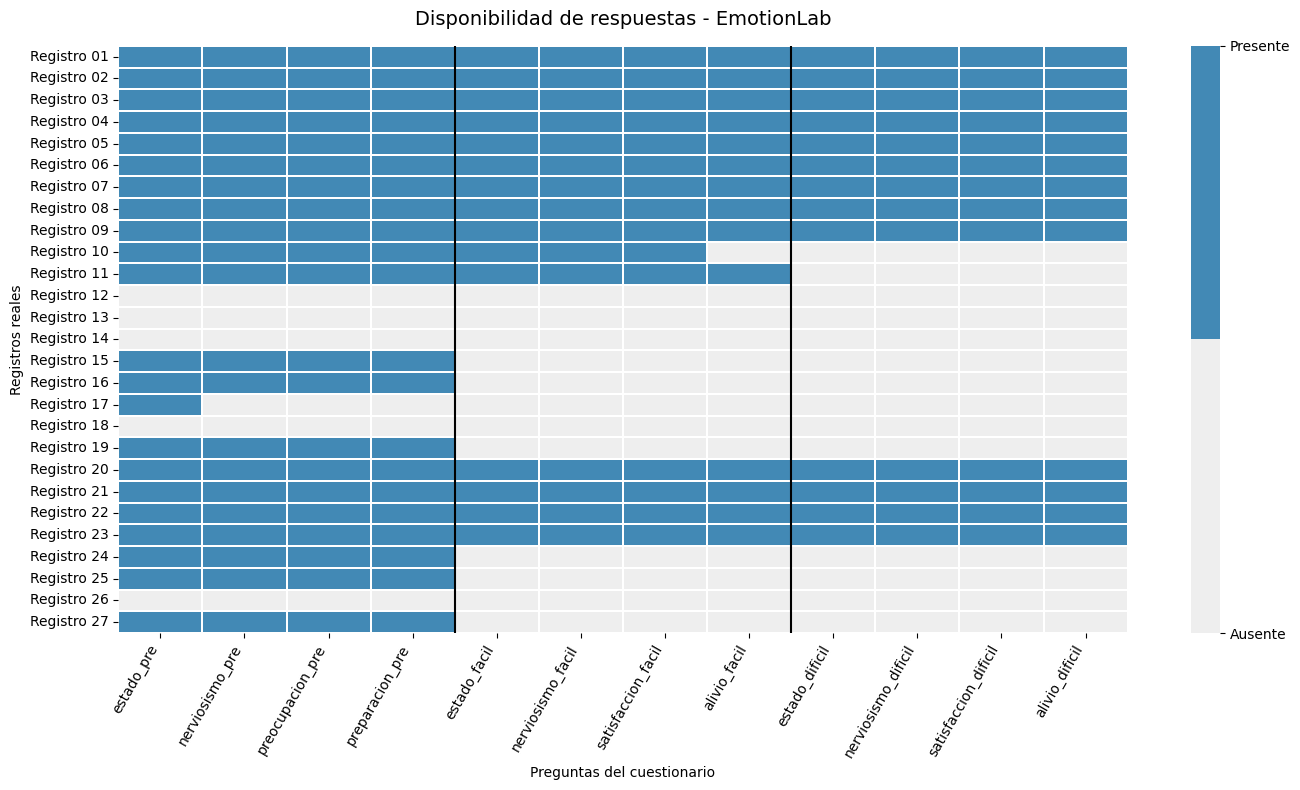

In [34]:

# =========================================================
# 3.3.3 - MAPA DE CALOR DE DISPONIBILIDAD
# =========================================================

# Creamos el espacio donde mostraremos el gráfico.

fig, ax = plt.subplots(figsize=(14, 8))

# Seaborn representa la matriz utilizando dos colores:
#
# Gris: respuesta ausente (0).
# Azul: respuesta disponible (1).

grafico = sns.heatmap(
    matriz_disponibilidad,
    cmap=["#eeeeee", "#4289b5"],
    vmin=0,
    vmax=1,
    linewidths=0.3,
    cbar_kws={"ticks": [0, 1]},
    ax=ax
)

# Agregamos etiquetas explicativas a la barra de colores.

barra = grafico.collections[0].colorbar
barra.set_ticks([0, 1])
barra.set_ticklabels(["Ausente", "Presente"])

# Marcamos visualmente los límites entre las fases
# para facilitar la comparación de sus respuestas.

ax.axvline(
    len(variables_iniciales),
    color="black",
    linewidth=1.5
)

ax.axvline(
    len(variables_iniciales) + len(variables_facil),
    color="black",
    linewidth=1.5
)

# Incorporamos títulos y etiquetas descriptivas.

ax.set_title(
    "Disponibilidad de respuestas - EmotionLab",
    fontsize=14,
    pad=15
)

ax.set_xlabel("Preguntas del cuestionario")
ax.set_ylabel("Registros reales")

plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)

# Ajustamos los espacios y mostramos el gráfico.

plt.tight_layout()
plt.show()


## **3.4 — Estadísticas descriptivas de las respuestas reales**

### ¿Qué realizaremos en esta sección?

En esta sección estudiaremos las respuestas de los **27 registros reales de EmotionLab** mediante estadísticas descriptivas, con el objetivo de comprender cómo se distribuyen las puntuaciones de las 12 preguntas del cuestionario.

Para ello, calcularemos tres grupos de indicadores:

- **Tendencia central:** media y mediana, que permiten conocer los valores alrededor de los cuales se concentran las respuestas.
- **Dispersión:** desviación estándar y rango intercuartílico, que ayudan a identificar qué tan diferentes son las respuestas entre estudiantes.
- **Distribución y disponibilidad:** cantidad de respuestas, valores mínimos, máximos y cuartiles, que permiten conocer el rango y la concentración de las puntuaciones.

### ¿Por qué es importante?

Porque antes de comparar el nerviosismo o el estado emocional entre las distintas fases, necesitamos comprender cómo se comportan las respuestas de cada pregunta.

Esto nos permitirá identificar tendencias, diferencias y variaciones que podrían resultar relevantes para los análisis posteriores de EmotionLab.

**Importante:** utilizaremos exclusivamente las respuestas reales disponibles, sin reemplazar los valores ausentes. Debido a que trabajamos con una escala ordinal de 1 a 9, daremos especial importancia a la mediana y los cuartiles.

In [35]:

# =========================================================
# 3.4.1 - CÁLCULO DE ESTADÍSTICAS DESCRIPTIVAS
# =========================================================

# Seleccionamos las 12 preguntas de los registros reales.
# Sus valores ya fueron convertidos y validados en el 3.1.

respuestas_eda = eda_reales[variables_cuestionario]

# describe() calcula automáticamente:
# cantidad, media, desviación estándar, mínimo,
# cuartiles (25%, 50%, 75%) y máximo.
#
# Pandas excluye los valores NaN de cada cálculo.
# .T coloca las preguntas en las filas de la tabla.

estadisticas = respuestas_eda.describe().T

print("Estadísticas descriptivas calculadas.")


Estadísticas descriptivas calculadas.


In [36]:

# =========================================================
# 3.4.2 - ORGANIZACIÓN DE LAS ESTADÍSTICAS
# =========================================================

# Reemplazamos los nombres técnicos por términos
# más fáciles de comprender durante la presentación.

estadisticas = estadisticas.rename(columns={
    "count": "Cantidad",
    "mean": "Media",
    "std": "Desviación estándar",
    "min": "Mínimo",
    "25%": "Q1",
    "50%": "Mediana",
    "75%": "Q3",
    "max": "Máximo"
})

# Calculamos el rango intercuartílico (Q3 - Q1).
# Representa la amplitud de la mitad central
# de las respuestas disponibles.

estadisticas["Rango intercuartílico"] = (
    estadisticas["Q3"] - estadisticas["Q1"]
)

# La cantidad de respuestas debe mostrarse como entero.
# Redondeamos las demás medidas a dos decimales.

estadisticas["Cantidad"] = estadisticas["Cantidad"].astype(int)
estadisticas = estadisticas.round(2)

print("Estadísticas organizadas correctamente.")


Estadísticas organizadas correctamente.


In [37]:

# =========================================================
# 3.4.3 - PRESENTACIÓN DE LAS ESTADÍSTICAS
# =========================================================

# Mostramos la tabla con los resultados de las 12 preguntas.
# Cada fila corresponde a una variable del cuestionario.

print("ESTADÍSTICAS DESCRIPTIVAS - EMOTIONLAB")
display(estadisticas)

# Verificamos que todas las preguntas estén incluidas.

if len(estadisticas) != len(variables_cuestionario):
    raise ValueError("Faltan variables en el resumen estadístico.")

print("\nAnálisis descriptivo completado.")


ESTADÍSTICAS DESCRIPTIVAS - EMOTIONLAB


,Cantidad,Media,Desviación estándar,Mínimo,Q1,Mediana,Q3,Máximo,Rango intercuartílico
estado_pre,22,4.36,3.14,1.0,1.25,3.5,7.0,9.0,5.75
nerviosismo_pre,21,4.19,2.69,1.0,2.00,3.0,6.0,9.0,4.00
preocupacion_pre,21,3.62,2.44,1.0,1.00,4.0,5.0,9.0,4.00
preparacion_pre,21,4.29,3.04,1.0,2.00,3.0,7.0,9.0,5.00
estado_facil,15,2.87,2.64,1.0,1.00,2.0,4.0,9.0,3.00
nerviosismo_facil,15,3.33,2.72,1.0,1.00,2.0,5.0,9.0,4.00
satisfaccion_facil,15,3.00,2.67,1.0,1.50,2.0,2.5,9.0,1.00
alivio_facil,14,2.71,2.13,1.0,1.00,2.5,3.0,8.0,2.00
estado_dificil,13,1.85,1.07,1.0,1.00,2.0,2.0,4.0,1.00
nerviosismo_dificil,13,2.77,2.13,1.0,1.00,3.0,3.0,9.0,2.00



Análisis descriptivo completado.


## **3.5 — Distribución de respuestas**

### ¿Qué realizaremos en esta sección?

En esta sección analizaremos cómo se distribuyen las respuestas de los estudiantes reales en las 12 preguntas de EmotionLab, utilizando gráficos de barras para representar la frecuencia de cada puntuación.

Para ello, realizaremos tres procesos:

- **Cálculo de frecuencias:** contaremos cuántas veces aparece cada valor de la escala de 1 a 9.
- **Organización de los gráficos:** distribuiremos las 12 preguntas según las fases inicial, fácil y difícil.
- **Visualización:** representaremos las frecuencias utilizando las mismas escalas para facilitar su comparación.

### ¿Por qué es importante?

Las estadísticas descriptivas permiten conocer valores generales, como la media y la mediana, pero no muestran cómo se distribuyen todas las respuestas.

Por ejemplo, dos preguntas podrían tener la misma media, aunque sus respuestas estén concentradas en valores muy diferentes.

Estos gráficos nos ayudarán a identificar concentraciones de respuestas, diferencias entre estudiantes y posibles patrones que podrían ser relevantes durante los siguientes análisis.

**Importante:** trabajaremos exclusivamente con los registros reales. Las respuestas ausentes no se incluirán en las frecuencias ni serán reemplazadas por valores estimados.

In [38]:

# =========================================================
# 3.5.1 - CÁLCULO DE FRECUENCIAS
# =========================================================

# Organizamos las preguntas según las tres fases
# para mantener un orden lógico en los gráficos.

variables_graficos = (
    list(variables_iniciales)
    + list(variables_facil)
    + list(variables_dificil)
)

# Verificamos que estén las 12 preguntas originales,
# sin variables faltantes ni repetidas.

if (
    len(variables_graficos) != 12
    or len(set(variables_graficos)) != 12
    or set(variables_graficos) != set(variables_cuestionario)
):
    raise ValueError("Revisa las variables del cuestionario.")

# Definimos la escala utilizada en EmotionLab.

escala = range(ESCALA_MINIMA, ESCALA_MAXIMA + 1)

# value_counts() cuenta cuántas veces aparece cada respuesta.
# reindex() incluye también las puntuaciones con frecuencia 0.
#
# Guardamos las frecuencias para reutilizarlas
# sin repetir los cálculos al generar los gráficos.

frecuencias_eda = {
    variable: eda_reales[variable]
    .value_counts()
    .reindex(escala, fill_value=0)
    for variable in variables_graficos
}

print("Frecuencias calculadas para las 12 preguntas.")


Frecuencias calculadas para las 12 preguntas.


Gráficos de distribución preparados.


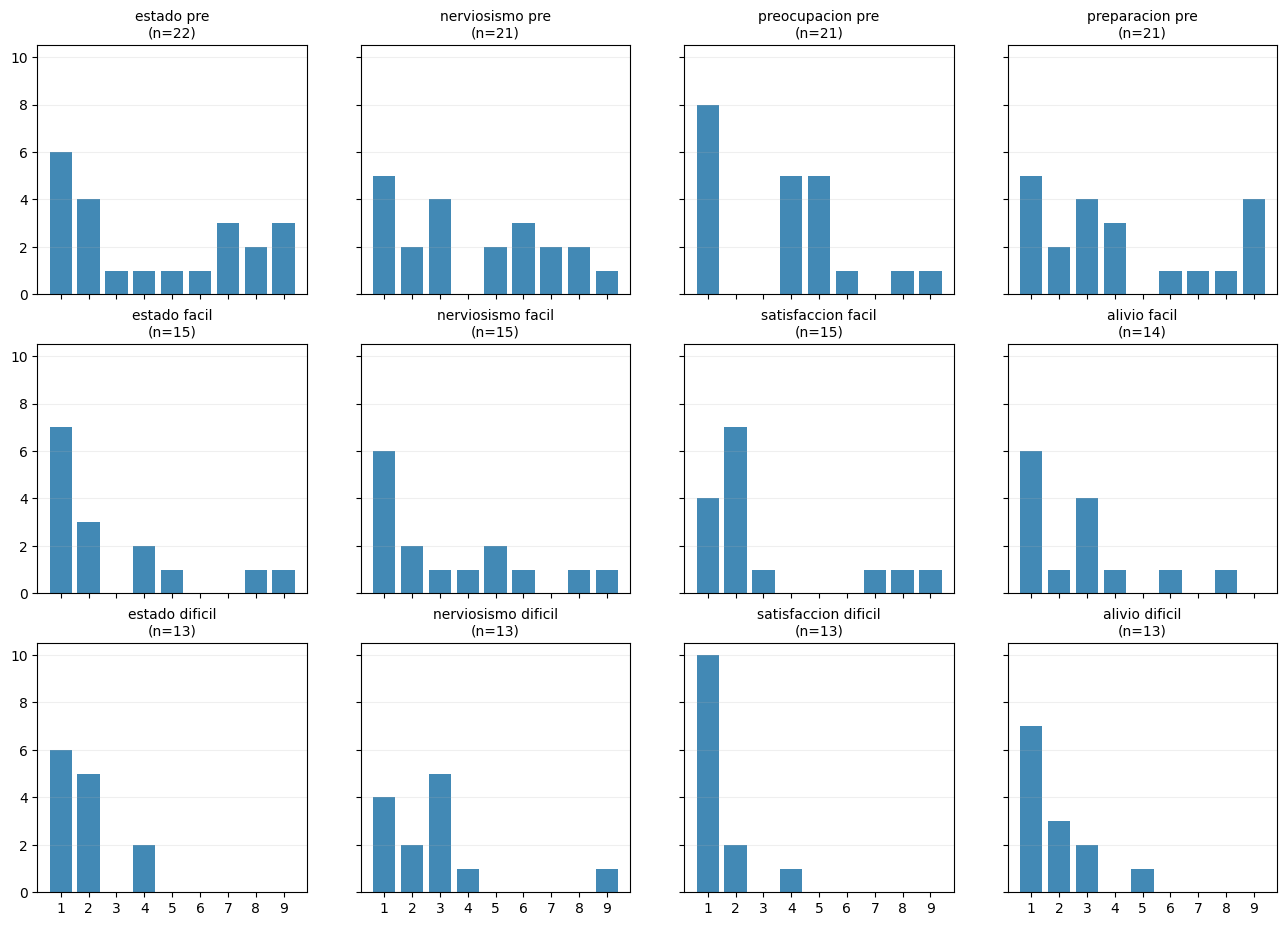

In [39]:

# =========================================================
# 3.5.2 - GRÁFICOS DE DISTRIBUCIÓN
# =========================================================

# Creamos una figura con 3 filas y 4 columnas.
#
# Cada fila representa una fase de EmotionLab:
# inicial, fácil y difícil.
#
# sharex y sharey permiten compartir las escalas
# para facilitar la comparación entre preguntas.

figura, ejes = plt.subplots(
    3, 4,
    figsize=(16, 11),
    sharex=True,
    sharey=True
)

# Recorremos las preguntas y asignamos un gráfico
# a cada variable utilizando los ejes disponibles.

for eje, variable in zip(ejes.flat, variables_graficos):

    frecuencias = frecuencias_eda[variable]

    # Representamos cuántos estudiantes seleccionaron
    # cada puntuación entre 1 y 9.

    eje.bar(
        frecuencias.index,
        frecuencias.values,
        color="#4289b5"
    )

    # Mostramos el nombre de la pregunta y su cantidad
    # de respuestas disponibles.
    #
    # n representa respuestas observadas, no el total
    # de los 27 estudiantes.

    eje.set_title(
        f"{variable.replace('_', ' ')}\n(n={frecuencias.sum()})",
        fontsize=10
    )

    eje.set_xticks(list(escala))
    eje.grid(axis="y", alpha=0.2)

print("Gráficos de distribución preparados.")


In [40]:

# =========================================================
# 3.5.3 - PRESENTACIÓN DE LAS DISTRIBUCIONES
# =========================================================

# Identificamos la frecuencia más alta de todas
# las preguntas para utilizar un mismo límite vertical.

frecuencia_maxima = max(
    frecuencias.max()
    for frecuencias in frecuencias_eda.values()
)

# Establecemos el mismo rango del eje vertical
# para evitar comparaciones visuales engañosas.

ejes[0, 0].set_ylim(
    0,
    max(1, frecuencia_maxima) + 0.5
)

# Agregamos etiquetas generales en lugar de repetir
# los nombres de los ejes en los 12 gráficos.

figura.supxlabel("Puntuación de respuesta (1 a 9)")
figura.supylabel("Cantidad de respuestas")

# Incorporamos un título que identifique el análisis.

figura.suptitle(
    "Distribución de respuestas reales - EmotionLab",
    fontsize=15
)

# Ajustamos los espacios y mostramos la figura.

plt.tight_layout()
plt.show()

print("Visualización de distribuciones completada.")


<Figure size 640x480 with 0 Axes>

Visualización de distribuciones completada.


## **3.6 — Comparación de las respuestas emocionales entre fases**

### ¿Qué realizaremos en esta sección?

En esta sección analizaremos las respuestas relacionadas con el **nerviosismo y el estado emocional** de los estudiantes durante los tres momentos de EmotionLab: inicial, dificultad fácil y dificultad difícil.

Para ello, realizaremos tres procesos:

- **Selección de indicadores:** identificaremos las preguntas de nerviosismo y estado emocional que se repiten en los tres formularios.
- **Organización de respuestas:** reuniremos las puntuaciones de cada fase para facilitar su comparación.
- **Visualización:** utilizaremos gráficos de caja (*boxplots*) y puntos individuales para observar medianas, dispersión y diferencias entre las respuestas.

### ¿Por qué es importante?

Porque necesitamos comprender si las respuestas emocionales presentan cambios entre los distintos momentos de la experiencia.

Los gráficos nos ayudarán a identificar tendencias que podrían resultar relevantes para comprender la tensión emocional percibida por los estudiantes.

**Importante:** las comparaciones serán exploratorias. No podremos afirmar que la dificultad de las presentaciones sea la causa de los cambios, y tampoco interpretaremos las puntuaciones como diagnósticos psicológicos.

In [41]:

# =========================================================
# 3.6.1 - SELECCIÓN DE LOS INDICADORES EMOCIONALES
# =========================================================

# EmotionLab registra nerviosismo y estado emocional
# en tres momentos de la experiencia.
#
# Organizamos las columnas según la fase a la que
# pertenece cada respuesta.

indicadores = {
    "Nerviosismo": {
        "Inicial": "nerviosismo_pre",
        "Fácil": "nerviosismo_facil",
        "Difícil": "nerviosismo_dificil"
    },
    "Estado emocional": {
        "Inicial": "estado_pre",
        "Fácil": "estado_facil",
        "Difícil": "estado_dificil"
    }
}

orden_etapas = ["Inicial", "Fácil", "Difícil"]

# Comprobamos que las seis variables estén disponibles
# en los registros reales preparados durante el 3.1.
#
# Si falta alguna, detenemos el análisis para evitar
# comparar información incorrecta.

variables_comparacion = [
    variable
    for columnas in indicadores.values()
    for variable in columnas.values()
]

faltantes = [
    variable for variable in variables_comparacion
    if variable not in eda_reales.columns
]

if faltantes:
    raise ValueError(
        f"Faltan indicadores emocionales: {faltantes}"
    )

print("Indicadores emocionales preparados correctamente.")
print("Variables seleccionadas:", len(variables_comparacion))


Indicadores emocionales preparados correctamente.
Variables seleccionadas: 6


In [42]:

# =========================================================
# 3.6.2 - ORGANIZACIÓN DE RESPUESTAS POR FASE
# =========================================================

# Seaborn necesita que las respuestas estén organizadas
# en columnas que indiquen la fase y su puntuación.
#
# melt() transforma las columnas originales en filas,
# dejando todas las respuestas bajo una misma estructura.

datos_indicadores = {}
resumen_indicadores = []

for nombre, columnas in indicadores.items():

    # Seleccionamos únicamente las tres preguntas
    # correspondientes al indicador.

    datos = eda_reales[list(columnas.values())].copy()

    # Cambiamos los nombres técnicos por las fases.
    # Por ejemplo: nerviosismo_pre pasa a ser Inicial.

    datos.columns = list(columnas.keys())

    # Unimos las respuestas en dos columnas:
    # Etapa: momento de la experiencia.
    # Respuesta: puntuación entregada por el estudiante.

    datos = datos.melt(
        var_name="Etapa",
        value_name="Respuesta"
    ).dropna(subset=["Respuesta"])

    # Conservamos solo las respuestas observadas.
    # No estimamos ni reemplazamos valores ausentes.

    datos_indicadores[nombre] = datos

    # Registramos la cantidad de respuestas y su mediana
    # para conocer el tamaño de cada grupo comparado.

    for etapa in orden_etapas:

        respuestas = datos.loc[
            datos["Etapa"] == etapa, "Respuesta"
        ]

        resumen_indicadores.append({
            "Indicador": nombre,
            "Etapa": etapa,
            "Respuestas": len(respuestas),
            "Mediana": respuestas.median()
        })

# Creamos una tabla resumida para revisar los datos.

tabla_indicadores = pd.DataFrame(resumen_indicadores)

print("RESPUESTAS EMOCIONALES POR FASE - EMOTIONLAB")
display(tabla_indicadores.round(2))


RESPUESTAS EMOCIONALES POR FASE - EMOTIONLAB


,Indicador,Etapa,Respuestas,Mediana
0,Nerviosismo,Inicial,21,3.0
1,Nerviosismo,Fácil,15,2.0
2,Nerviosismo,Difícil,13,3.0
3,Estado emocional,Inicial,22,3.5
4,Estado emocional,Fácil,15,2.0
5,Estado emocional,Difícil,13,2.0


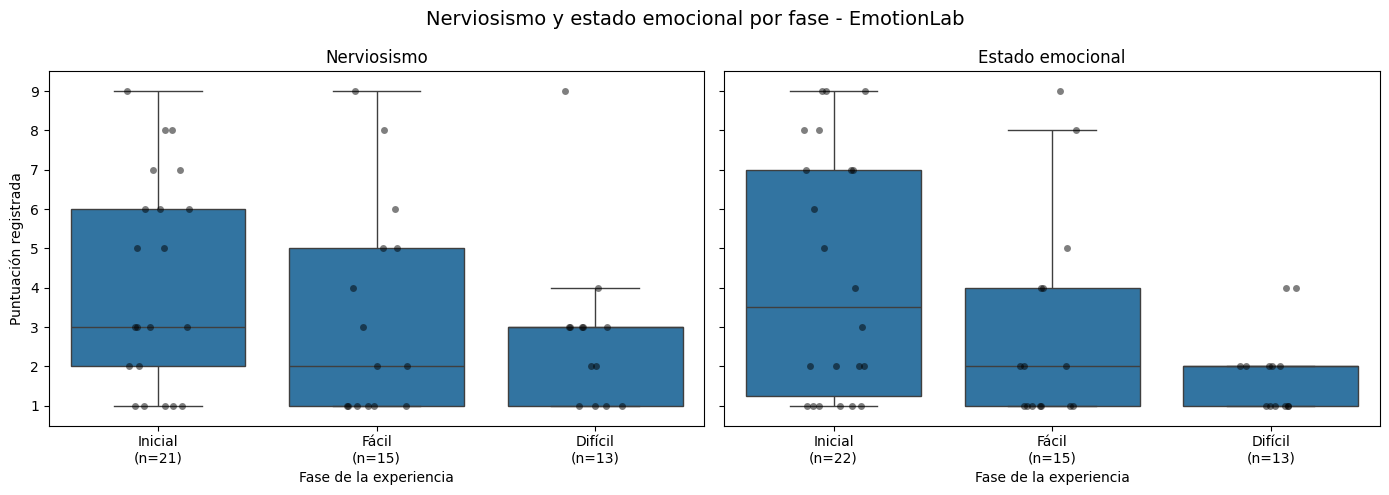

Comparación exploratoria completada.


In [43]:

# =========================================================
# 3.6.3 - COMPARACIÓN EMOCIONAL ENTRE FASES
# =========================================================

# Creamos dos gráficos en una misma figura.
# sharey=True mantiene la misma escala vertical
# para ambos indicadores.

figura, ejes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    sharey=True
)

for eje, (nombre, datos) in zip(
    ejes, datos_indicadores.items()
):

    # Si no existen respuestas, mostramos un aviso
    # en lugar de generar un gráfico vacío.

    if datos.empty:
        eje.set_title(nombre)
        eje.text(
            0.5, 0.5,
            "Sin respuestas disponibles",
            ha="center",
            va="center",
            transform=eje.transAxes
        )
        eje.set_xticks([])
        continue

    # El boxplot muestra la mediana, los cuartiles
    # y la dispersión de las respuestas.
    #
    # Ocultamos los puntos extremos del boxplot
    # porque los mostraremos con stripplot.

    sns.boxplot(
        data=datos,
        x="Etapa",
        y="Respuesta",
        order=orden_etapas,
        showfliers=False,
        ax=eje
    )

    # Agregamos las respuestas individuales.
    #
    # jitter separa ligeramente los puntos para
    # que no queden todos superpuestos.
    #
    # Esto permite observar las puntuaciones reales,
    # incluyendo los posibles valores extremos.

    sns.stripplot(
        data=datos,
        x="Etapa",
        y="Respuesta",
        order=orden_etapas,
        color="black",
        alpha=0.5,
        jitter=0.15,
        ax=eje
    )

    # Mostramos cuántas respuestas tiene cada fase.
    # Es importante porque no todos los estudiantes
    # completaron los tres formularios.

    etiquetas = [
        f"{etapa}\n(n={(datos['Etapa'] == etapa).sum()})"
        for etapa in orden_etapas
    ]

    eje.set_xticks(range(len(orden_etapas)))
    eje.set_xticklabels(etiquetas)

    # Utilizamos la misma escala de 1 a 9
    # para facilitar la comparación de resultados.

    eje.set_title(nombre)
    eje.set_xlabel("Fase de la experiencia")
    eje.set_ylabel("Puntuación registrada")
    eje.set_ylim(ESCALA_MINIMA - 0.5, ESCALA_MAXIMA + 0.5)

# Agregamos el título general de la figura.

figura.suptitle(
    "Nerviosismo y estado emocional por fase - EmotionLab",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Comparación exploratoria completada.")


## **3.7 — Análisis de correlaciones**

### ¿Qué realizaremos en esta sección?

Analizaremos las relaciones entre las 12 variables de EmotionLab utilizando el coeficiente de correlación de **Spearman**, un método adecuado para explorar asociaciones entre respuestas ordinales.

Dividiremos el análisis en cuatro partes:

- **Preparación:** seleccionaremos las respuestas reales que utilizaremos en las correlaciones.
- **Cálculo:** identificaremos las asociaciones entre variables y la cantidad de estudiantes disponibles para cada comparación.
- **Revisión:** organizaremos los resultados en tablas para comprender qué correlaciones pudieron calcularse.
- **Visualización:** generaremos un mapa de calor que permita identificar asociaciones positivas y negativas.

### ¿Por qué es importante?

Este análisis nos ayudará a comprender si determinadas respuestas tienden a variar conjuntamente. Por ejemplo, podremos explorar si los estudiantes que declaran mayor nerviosismo también presentan ciertas tendencias en sus respuestas de preparación o satisfacción.

Esto puede aportar información relevante para comprender las relaciones entre las variables antes de desarrollar el modelo de Machine Learning.

**Consideración:** una correlación no demuestra causalidad. Además, trabajaremos exclusivamente con los datos reales disponibles y exigiremos un mínimo de cinco estudiantes con respuestas en ambas variables para calcular cada correlación exploratoria.

In [44]:

# =========================================================
# 3.7.1 - PREPARACIÓN DE LOS DATOS PARA CORRELACIONES
# =========================================================

# Utilizamos los registros reales preparados en el 3.1.
# No incorporamos datos sintéticos ni estimamos respuestas.

# Verificamos que las variables del cuestionario existan
# y no estén repetidas.

faltantes = [
    variable for variable in variables_cuestionario
    if variable not in eda_reales.columns
]

if faltantes or len(set(variables_cuestionario)) != 12:
    raise ValueError(
        f"Revisa las 12 variables del cuestionario. "
        f"Columnas faltantes: {faltantes}"
    )

# Seleccionamos únicamente las respuestas que analizaremos.
# No es necesario crear otra copia porque no las modificaremos.

respuestas_correlacion = eda_reales[variables_cuestionario]

print("Variables preparadas:", respuestas_correlacion.shape[1])
print("Registros reales:", len(respuestas_correlacion))


Variables preparadas: 12
Registros reales: 27


In [45]:

# =========================================================
# 3.7.2 - CÁLCULO DE CORRELACIONES DE SPEARMAN
# =========================================================

# Establecemos el mínimo de pares necesarios.
# Cada par corresponde a un estudiante que respondió
# las dos preguntas que estamos comparando.

minimo_pares = 5

# corr() calcula las asociaciones de Spearman.
# min_periods evita calcular correlaciones cuando
# existen menos de cinco pares válidos.
#
# Pandas excluye los NaN de cada comparación sin
# eliminar al estudiante de todos los demás análisis.

matriz_correlacion = respuestas_correlacion.corr(
    method="spearman",
    min_periods=minimo_pares
)

# Creamos una matriz donde:
# 1 = respuesta presente.
# 0 = respuesta ausente.

presencia = respuestas_correlacion.notna().astype(int)

# Multiplicamos la matriz transpuesta por la original.
# Así contamos cuántos estudiantes tienen respuestas
# disponibles en cada combinación de preguntas.

matriz_pares = presencia.T @ presencia

print("Correlaciones de Spearman calculadas.")
print("Mínimo de pares exigidos:", minimo_pares)


Correlaciones de Spearman calculadas.
Mínimo de pares exigidos: 5


In [46]:

# =========================================================
# 3.7.3 - REVISIÓN DE LOS RESULTADOS
# =========================================================

# Primero mostramos cuántos estudiantes tienen
# respuestas disponibles para cada par de variables.

print("ESTUDIANTES DISPONIBLES POR COMPARACIÓN")
display(matriz_pares)

# Después mostramos los coeficientes de Spearman.
# Redondeamos a dos decimales para facilitar la lectura.

print("\nMATRIZ DE CORRELACIONES - EMOTIONLAB")
display(matriz_correlacion.round(2))

# Identificamos las correlaciones que no pudieron
# calcularse por falta de datos o ausencia de variación.
#
# Estos valores aparecerán como NaN y NO deben
# interpretarse como correlaciones iguales a cero.

correlaciones_ausentes = matriz_correlacion.isna()

print("\nRevisión de correlaciones completada.")


ESTUDIANTES DISPONIBLES POR COMPARACIÓN


,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
estado_pre,22,21,21,21,15,15,15,14,13,13,13,13
nerviosismo_pre,21,21,21,21,15,15,15,14,13,13,13,13
preocupacion_pre,21,21,21,21,15,15,15,14,13,13,13,13
preparacion_pre,21,21,21,21,15,15,15,14,13,13,13,13
estado_facil,15,15,15,15,15,15,15,14,13,13,13,13
nerviosismo_facil,15,15,15,15,15,15,15,14,13,13,13,13
satisfaccion_facil,15,15,15,15,15,15,15,14,13,13,13,13
alivio_facil,14,14,14,14,14,14,14,14,13,13,13,13
estado_dificil,13,13,13,13,13,13,13,13,13,13,13,13
nerviosismo_dificil,13,13,13,13,13,13,13,13,13,13,13,13



MATRIZ DE CORRELACIONES - EMOTIONLAB


,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
estado_pre,1.00,0.56,0.17,0.73,0.65,0.42,0.52,0.30,0.11,0.13,0.21,0.43
nerviosismo_pre,0.56,1.00,0.29,0.52,0.51,0.49,0.70,0.31,0.13,0.25,0.07,0.43
preocupacion_pre,0.17,0.29,1.00,0.24,-0.09,-0.11,-0.05,-0.03,0.45,0.60,0.29,-0.07
preparacion_pre,0.73,0.52,0.24,1.00,0.70,0.69,0.43,0.75,0.35,0.64,0.08,0.59
estado_facil,0.65,0.51,-0.09,0.70,1.00,0.76,0.74,0.75,0.24,0.22,0.20,0.51
nerviosismo_facil,0.42,0.49,-0.11,0.69,0.76,1.00,0.67,0.84,0.16,0.39,0.17,0.54
satisfaccion_facil,0.52,0.70,-0.05,0.43,0.74,0.67,1.00,0.60,0.10,-0.00,-0.25,0.20
alivio_facil,0.30,0.31,-0.03,0.75,0.75,0.84,0.60,1.00,0.29,0.62,0.07,0.58
estado_dificil,0.11,0.13,0.45,0.35,0.24,0.16,0.10,0.29,1.00,0.55,0.49,0.15
nerviosismo_dificil,0.13,0.25,0.60,0.64,0.22,0.39,-0.00,0.62,0.55,1.00,0.44,0.65



Revisión de correlaciones completada.


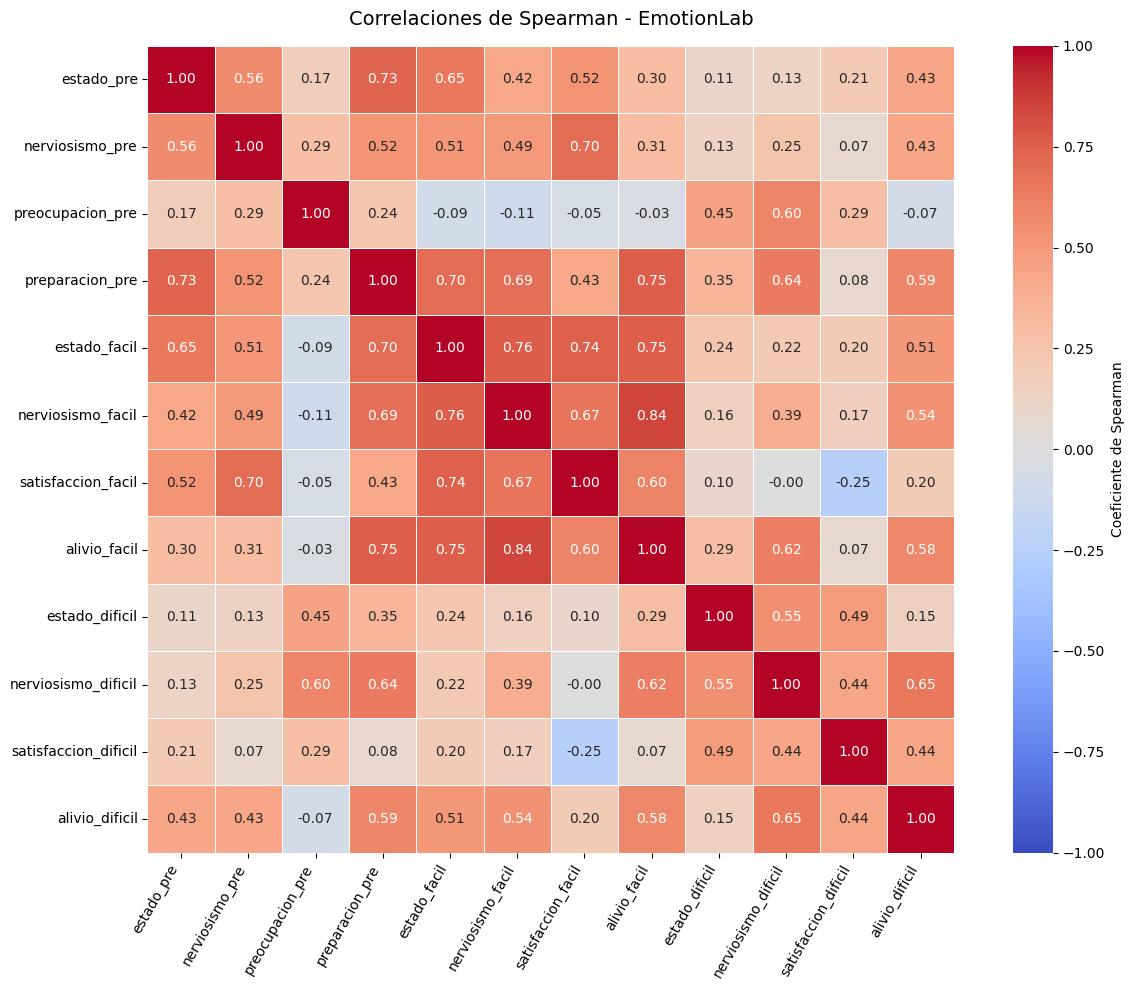

Mapa de correlaciones generado correctamente.


In [47]:

# =========================================================
# 3.7.4 - MAPA DE CALOR DE CORRELACIONES
# =========================================================

# Verificamos que exista al menos una correlación válida.
# Si todas son NaN, no generaremos un gráfico vacío.

if matriz_correlacion.notna().any().any():

    # Creamos el espacio donde mostraremos el mapa.

    fig, ax = plt.subplots(figsize=(13, 10))

    # Cada celda representa la correlación entre dos preguntas.
    #
    # Rojo: asociación positiva.
    # Azul: asociación negativa.
    # Valores cercanos a 0: asociación monotónica débil.
    #
    # mask oculta las correlaciones que no se pudieron
    # calcular por falta de datos o variación.

    sns.heatmap(
        matriz_correlacion,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        mask=correlaciones_ausentes,
        linewidths=0.4,
        square=True,
        cbar_kws={"label": "Coeficiente de Spearman"},
        ax=ax
    )

    # Ajustamos el título y las etiquetas para que
    # las 12 variables puedan identificarse claramente.

    ax.set_title(
        "Correlaciones de Spearman - EmotionLab",
        fontsize=14,
        pad=15
    )

    plt.xticks(rotation=60, ha="right")
    plt.yticks(rotation=0)

    plt.tight_layout()
    plt.show()

    print("Mapa de correlaciones generado correctamente.")

else:
    print("No existen correlaciones suficientes para graficar.")


##**3.8 — Perfil global del estudiante**

### ¿Qué realizaremos en esta sección?

Construiremos un perfil descriptivo individual de los estudiantes de EmotionLab, utilizando las respuestas registradas durante las fases inicial, fácil y difícil.

Para ello, realizaremos tres procesos:

- **Selección:** identificaremos a los estudiantes que completaron las 12 preguntas de los tres formularios.
- **Cálculo de indicadores:** obtendremos la mediana del nerviosismo, la mediana del estado emocional y los cambios numéricos entre el inicio y el final.
- **Resumen:** presentaremos los perfiles individuales y sus estadísticas descriptivas generales.

### ¿Por qué es importante?

Los análisis anteriores nos permitieron conocer las tendencias generales de los estudiantes. Sin embargo, esas tendencias no muestran necesariamente lo que ocurrió con cada participante.

Este apartado nos ayudará a identificar diferencias individuales y estudiar cómo cambiaron las puntuaciones de un mismo estudiante durante la experiencia.

**Importante:** los indicadores calculados son descriptivos. No representan todavía el índice de tensión de EmotionLab ni permiten determinar niveles clínicos de estrés.

Trabajaremos únicamente con estudiantes que tengan las 12 respuestas completas, sin estimar valores faltantes.

In [48]:

# =========================================================
# 3.8.1 - SELECCIÓN DE PERFILES COMPLETOS
# =========================================================

# Para construir un perfil global necesitamos conocer
# las respuestas de las tres fases de EmotionLab.
#
# Seleccionamos únicamente los registros que contienen
# las 12 preguntas completas del cuestionario.

perfiles_completos = eda_reales.dropna(
    subset=variables_cuestionario
).copy()

# Definimos las preguntas que representan nerviosismo
# y estado emocional en cada momento de la experiencia.
#
# Conservamos el orden: Inicial, Fácil y Difícil.

columnas_nerviosismo = [
    "nerviosismo_pre",
    "nerviosismo_facil",
    "nerviosismo_dificil"
]

columnas_estado = [
    "estado_pre",
    "estado_facil",
    "estado_dificil"
]

# Comprobamos que las variables y el identificador
# estén disponibles antes de realizar los cálculos.

columnas_requeridas = (
    columnas_nerviosismo
    + columnas_estado
    + ["id_estudiante"]
)

faltantes = [
    columna for columna in columnas_requeridas
    if columna not in perfiles_completos.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas para el perfil: {faltantes}")

print("Registros reales:", len(eda_reales))
print("Perfiles completos:", len(perfiles_completos))


Registros reales: 27
Perfiles completos: 13


In [49]:

# =========================================================
# 3.8.2 - CÁLCULO DEL PERFIL GLOBAL
# =========================================================

# Calculamos la mediana de nerviosismo y estado emocional
# utilizando las respuestas de las tres fases.
#
# median(axis=1) calcula el valor central por estudiante,
# en lugar de calcularlo para todos los participantes.

perfiles_completos["mediana_nerviosismo"] = (
    perfiles_completos[columnas_nerviosismo].median(axis=1)
)

perfiles_completos["mediana_estado"] = (
    perfiles_completos[columnas_estado].median(axis=1)
)

# Calculamos el cambio entre la evaluación final
# (dificultad difícil) y la evaluación inicial.
#
# Cambio positivo: la puntuación final es mayor.
# Cambio negativo: la puntuación final es menor.
# Cambio cero: ambas puntuaciones son iguales.

perfiles_completos["cambio_nerviosismo"] = (
    perfiles_completos["nerviosismo_dificil"]
    - perfiles_completos["nerviosismo_pre"]
)

perfiles_completos["cambio_estado"] = (
    perfiles_completos["estado_dificil"]
    - perfiles_completos["estado_pre"]
)

# Estos cambios representan diferencias numéricas.
# Su interpretación emocional depende del significado
# de cada escala utilizada en Unity.

print("Indicadores individuales calculados correctamente.")


Indicadores individuales calculados correctamente.


In [50]:

# =========================================================
# 3.8.3 - RESUMEN DE LOS PERFILES GLOBALES
# =========================================================

# Seleccionamos los cuatro indicadores calculados
# para construir una tabla descriptiva individual.

columnas_perfil = [
    "mediana_nerviosismo",
    "mediana_estado",
    "cambio_nerviosismo",
    "cambio_estado"
]

# Conservamos el identificador seudónimo para mantener
# la correspondencia con los registros originales.

perfil_global = perfiles_completos[
    ["id_estudiante"] + columnas_perfil
].copy()

print("PERFIL GLOBAL - EMOTIONLAB")
print("Estudiantes analizados:", len(perfil_global))

if not perfil_global.empty:

    # Para mostrar los resultados utilizamos etiquetas
    # temporales, evitando exponer identificadores
    # originales durante la presentación.

    perfil_presentacion = perfil_global.copy()

    perfil_presentacion["id_estudiante"] = [
        f"Registro {i:02d}"
        for i in range(1, len(perfil_global) + 1)
    ]

    display(perfil_presentacion)

    # describe() resume la distribución de los indicadores
    # entre los estudiantes con cuestionarios completos.
    #
    # Calcula cantidad, media, mediana, desviación estándar,
    # valores mínimos, máximos y cuartiles.

    print("\nRESUMEN ESTADÍSTICO DE LOS PERFILES")
    display(perfil_global[columnas_perfil].describe().round(2))

else:
    print("No existen cuestionarios completos para este análisis.")

print("\nAnálisis de perfiles globales finalizado.")


PERFIL GLOBAL - EMOTIONLAB
Estudiantes analizados: 13


,id_estudiante,mediana_nerviosismo,mediana_estado,cambio_nerviosismo,cambio_estado
0,Registro 01,3.0,1.0,0.0,3.0
1,Registro 02,3.0,2.0,0.0,0.0
2,Registro 03,1.0,1.0,2.0,3.0
3,Registro 04,2.0,2.0,-3.0,-1.0
4,Registro 05,3.0,2.0,0.0,0.0
5,Registro 06,1.0,1.0,0.0,0.0
6,Registro 07,2.0,1.0,7.0,0.0
7,Registro 08,1.0,1.0,0.0,0.0
8,Registro 09,1.0,1.0,0.0,-5.0
19,Registro 10,1.0,1.0,-4.0,0.0



RESUMEN ESTADÍSTICO DE LOS PERFILES


,mediana_nerviosismo,mediana_estado,cambio_nerviosismo,cambio_estado
count,13.00,13.00,13.00,13.00
mean,2.15,1.54,-0.31,-0.46
std,1.21,0.88,2.84,2.37
min,1.00,1.00,-4.00,-5.00
25%,1.00,1.00,-2.00,-1.00
50%,2.00,1.00,0.00,0.00
75%,3.00,2.00,0.00,0.00
max,5.00,4.00,7.00,3.00



Análisis de perfiles globales finalizado.


##**3.9 — Revisión exploratoria de valores extremos**

### ¿Qué realizaremos en esta sección?

En esta sección revisaremos las respuestas de los estudiantes reales de EmotionLab para identificar puntuaciones que se encuentren alejadas de la distribución central de cada pregunta.

Utilizaremos el **rango intercuartílico (IQR)**, un método estadístico que permite detectar posibles valores extremos mediante los cuartiles Q1 y Q3.

El análisis se dividirá en tres partes:

- **Cálculo de cuartiles:** obtendremos Q1, Q3 y el rango intercuartílico de las 12 preguntas.
- **Identificación de valores extremos:** calcularemos los límites estadísticos y contaremos las respuestas que se encuentren fuera de ellos.
- **Revisión de resultados:** presentaremos una tabla para reconocer qué variables contienen posibles valores extremos.

### ¿Por qué es importante?

Este procedimiento nos permitirá identificar respuestas poco frecuentes y estudiar la variabilidad existente entre los estudiantes.

Sin embargo, **un valor extremo no necesariamente es una respuesta incorrecta**. Por ejemplo, si la mayoría de los participantes responde 1 en una pregunta, una respuesta de 8 podría identificarse como extrema y seguir siendo válida dentro de la escala de EmotionLab.

Por esta razón, no eliminaremos ni modificaremos las respuestas identificadas. El análisis será exclusivamente descriptivo y utilizará los registros reales disponibles.

In [51]:

# =========================================================
# 3.9.1 - CÁLCULO DEL RANGO INTERCUARTÍLICO
# =========================================================

# Utilizamos las 12 preguntas de los registros reales.
# Los valores ausentes se excluyen automáticamente
# del cálculo de los cuartiles.

respuestas_extremos = eda_reales[variables_cuestionario]

# Calculamos Q1 (25 %) y Q3 (75 %) para cada pregunta.
#
# Q1: primer cuartil de las respuestas.
# Q3: tercer cuartil de las respuestas.

cuartiles = respuestas_extremos.quantile([0.25, 0.75])

q1 = cuartiles.loc[0.25]
q3 = cuartiles.loc[0.75]

# El IQR representa la diferencia entre Q3 y Q1.
# Nos permite medir la dispersión de la mitad
# central de las respuestas de cada variable.

rango_iqr = q3 - q1

print("Cuartiles y rangos intercuartílicos calculados.")


Cuartiles y rangos intercuartílicos calculados.


In [52]:

# =========================================================
# 3.9.2 - IDENTIFICACIÓN DE VALORES EXTREMOS
# =========================================================

# Establecemos los límites estadísticos:
#
# Inferior = Q1 - 1.5 * IQR
# Superior = Q3 + 1.5 * IQR
#
# Una respuesta fuera de estos límites será
# considerada un posible valor extremo por IQR.

limite_inferior = q1 - 1.5 * rango_iqr
limite_superior = q3 + 1.5 * rango_iqr

# Comparamos las respuestas de cada pregunta
# con sus límites correspondientes.
#
# lt() identifica valores menores al límite inferior.
# gt() identifica valores mayores al límite superior.
#
# axis="columns" permite comparar cada columna
# con el límite calculado para esa misma pregunta.

marcas_extremos = (
    respuestas_extremos.lt(limite_inferior, axis="columns")
    | respuestas_extremos.gt(limite_superior, axis="columns")
)

# Contamos cuántas respuestas fueron evaluadas
# y cuántas se encuentran fuera de los límites.

cantidad_respuestas = respuestas_extremos.count()
cantidad_extremos = marcas_extremos.sum()

# Si una pregunta no tiene respuestas disponibles,
# dejamos su cantidad de extremos sin calcular (NaN).
# No debemos confundir "sin datos" con "cero extremos".

cantidad_extremos = cantidad_extremos.where(
    cantidad_respuestas.gt(0),
    np.nan
)

print("Posibles valores extremos identificados.")


Posibles valores extremos identificados.


In [53]:

# =========================================================
# 3.9.3 - RESUMEN DE LOS VALORES EXTREMOS
# =========================================================

# Organizamos los resultados de las 12 preguntas.
# Cada fila mostrará sus respuestas disponibles,
# límites estadísticos y cantidad de posibles extremos.

tabla_extremos = pd.DataFrame({
    "Variable": variables_cuestionario,
    "Respuestas evaluadas": cantidad_respuestas.values,
    "Límite inferior": limite_inferior.values,
    "Límite superior": limite_superior.values,
    "Valores extremos por IQR": cantidad_extremos.values
})

# Redondeamos solamente la visualización.
# Los cálculos anteriores mantienen su precisión original.

print("REVISIÓN DE VALORES EXTREMOS - EMOTIONLAB")
display(tabla_extremos.round(2))

# Sumamos las respuestas identificadas como extremas.
# Este total representa respuestas, no estudiantes únicos.

total_extremos = int(cantidad_extremos.sum())

print("\nRespuestas evaluadas:", int(cantidad_respuestas.sum()))
print("Posibles valores extremos:", total_extremos)

# Una variable con IQR = 0 tiene Q1 y Q3 iguales.
# En ese caso, cualquier puntuación distinta de ese
# valor central puede quedar marcada como extrema.
#
# Esto requiere especial precaución con muestras pequeñas.

variables_iqr_cero = rango_iqr[
    rango_iqr.eq(0) & cantidad_respuestas.gt(0)
].index.tolist()

if variables_iqr_cero:
    print("\nAtención: variables con IQR igual a cero:")
    print(", ".join(variables_iqr_cero))

# Recordamos que las puntuaciones identificadas
# no se eliminan ni modifican en el dataset.

print(
    "\nAnálisis exploratorio completado. "
    "No se modificaron ni eliminaron respuestas."
)


REVISIÓN DE VALORES EXTREMOS - EMOTIONLAB


,Variable,Respuestas evaluadas,Límite inferior,Límite superior,Valores extremos por IQR
0,estado_pre,22,-7.38,15.62,0
1,nerviosismo_pre,21,-4.00,12.00,0
2,preocupacion_pre,21,-5.00,11.00,0
3,preparacion_pre,21,-5.50,14.50,0
4,estado_facil,15,-3.50,8.50,1
5,nerviosismo_facil,15,-5.00,11.00,0
6,satisfaccion_facil,15,0.00,4.00,3
7,alivio_facil,14,-2.00,6.00,1
8,estado_dificil,13,-0.50,3.50,2
9,nerviosismo_dificil,13,-2.00,6.00,1



Respuestas evaluadas: 196
Posibles valores extremos: 12

Atención: variables con IQR igual a cero:
satisfaccion_dificil

Análisis exploratorio completado. No se modificaron ni eliminaron respuestas.


## Conclusión de la Etapa 3: Análisis Exploratorio de Datos (EDA)

Durante esta etapa analizamos las respuestas de los estudiantes reales de EmotionLab, con el objetivo de comprender cómo se distribuyen sus puntuaciones, identificar posibles relaciones entre variables y estudiar las diferencias observadas durante las tres fases de la experiencia.

El análisis se realizó exclusivamente con los **27 registros reales**, sin incorporar datos sintéticos ni reemplazar respuestas faltantes.

### 1. Preparación y disponibilidad de los datos

Comenzamos verificando que las respuestas estuvieran correctamente preparadas para los análisis estadísticos.

Los principales resultados fueron:

- **12 variables** correspondientes a los tres cuestionarios.
- **196 respuestas disponibles** de 324 posibles (60,49 %).
- **128 respuestas ausentes** (39,51 %).
- **13 estudiantes** con los tres formularios completamente respondidos.

También observamos que la disponibilidad de cuestionarios completos disminuyó entre las fases: 21 en la inicial, 14 en la fácil y 13 en la difícil.

### 2. Distribución y comportamiento de las respuestas

Mediante estadísticas descriptivas, gráficos de barras y diagramas de caja estudiamos cómo se distribuyeron las puntuaciones.

Al comparar las medianas de los principales indicadores, obtuvimos:

| Indicador | Inicial | Fácil | Difícil |
|---|---:|---:|---:|
| Nerviosismo | 3 | 2 | 3 |
| Estado emocional | 3,5 | 2 | 2 |

Estos resultados muestran diferencias entre las distribuciones de las tres fases. Sin embargo, no necesariamente representan cambios individuales, porque la cantidad de respuestas disponibles varía entre formularios.

Además, la interpretación del estado emocional depende del significado de la escala utilizada en Unity.

### 3. Correlaciones y perfiles individuales

El análisis de Spearman permitió identificar asociaciones entre algunas respuestas.

Una de las correlaciones más elevadas se observó entre **nerviosismo y alivio en la fase fácil (ρ = 0,84)**. No obstante, estas relaciones son exploratorias y no demuestran causalidad.

También construimos perfiles descriptivos para los **13 estudiantes con cuestionarios completos**, calculando sus medianas y cambios individuales entre el inicio y el final de la experiencia.

Estos perfiles nos permitieron reconocer diferencias entre participantes que no siempre resultan visibles al observar únicamente las estadísticas generales.

### 4. Revisión de valores extremos

Mediante el criterio del rango intercuartílico identificamos **12 respuestas potencialmente extremas** entre las 196 respuestas disponibles.

También observamos que la variable `satisfaccion_dificil` presentó un rango intercuartílico igual a cero, debido a la concentración de puntuaciones en el valor 1.

Estas respuestas no se consideraron errores automáticamente, ya que todas permanecen dentro de la escala válida de EmotionLab.

Por esta razón, **no eliminamos ni modificamos ninguna respuesta** durante el análisis.

### 5. Resultado final de la etapa

La Etapa 3 nos permitió conocer mejor las características de los datos recopilados e identificar aspectos importantes para continuar con el proyecto:

- Las respuestas presentan diferentes distribuciones y niveles de variabilidad.
- Existen asociaciones exploratorias entre determinadas variables.
- La información faltante limita algunas comparaciones entre fases.
- Los perfiles individuales permiten complementar los resultados generales.
- La cantidad reducida de participantes exige interpretar los resultados con precaución.

**En conclusión**, logramos establecer una base estadística para comprender las respuestas de los estudiantes y orientar las siguientes etapas de EmotionLab.

Estos resultados servirán como referencia para continuar con el desarrollo experimental del sistema, manteniendo una distinción clara entre las respuestas observadas, los indicadores descriptivos y las futuras agrupaciones de Machine Learning.

Es importante destacar que los resultados obtenidos **no constituyen diagnósticos psicológicos ni permiten generalizar conclusiones a toda la población estudiantil**.

# Etapa 4: Construcción del índice exploratorio de tensión percibida

## Objetivo

Durante esta etapa desarrollaremos un procedimiento para resumir las respuestas emocionales de los estudiantes y obtener un **índice global de tensión percibida** durante la experiencia de EmotionLab.

A diferencia de los análisis anteriores, donde estudiamos las respuestas individualmente, ahora buscaremos combinar la información de las tres fases para obtener un resultado general de cada participante.

### 1. Indicadores que utilizaremos

El índice se construirá a partir de dos variables presentes en los tres cuestionarios:

- **Nerviosismo:** permitirá representar la intensidad de nerviosismo declarada por el estudiante.
- **Estado emocional:** funcionará como un indicador complementario para interpretar su experiencia.

Asignaremos una mayor ponderación al nerviosismo y revisaremos la orientación de ambas escalas antes de combinar las respuestas.

### 2. Construcción del índice

Desarrollaremos el cálculo mediante tres procesos:

- **Análisis por fase:** combinaremos los indicadores de nerviosismo y estado emocional de cada formulario.
- **Índice global:** integraremos los resultados de las fases inicial, fácil y difícil.
- **Clasificación exploratoria:** estudiaremos criterios para interpretar el índice mediante tres categorías.

Las categorías propuestas son:

- **Estado de calma:** tensión percibida relativamente baja.
- **Tensión moderada:** valores intermedios del índice.
- **Tensión elevada:** tensión percibida relativamente alta.

Las ponderaciones y los límites de estas categorías deberán documentarse y evaluarse antes de utilizarlos como una clasificación definitiva.

### 3. Tratamiento de respuestas incompletas

Consideraremos la disponibilidad de información antes de calcular el índice:

- **Tres fases completas:** permitirán calcular el índice global sin estimaciones.
- **Dos fases completas:** estudiaremos si es viable estimar la fase faltante utilizando las respuestas del mismo estudiante.
- **Una fase completa:** podremos mostrar información parcial, pero no asignaremos una clasificación global equivalente a una experiencia completa.

Cualquier valor estimado deberá distinguirse claramente de las respuestas observadas.

### 4. Diferencia con Machine Learning

EmotionLab utilizará dos procedimientos con propósitos diferentes:

- **Índice de tensión percibida:** aplicará una fórmula definida por el proyecto para resumir las respuestas emocionales.
- **Machine Learning no supervisado:** buscará identificar grupos de estudiantes con patrones de respuesta similares.

Esto significa que el modelo de Machine Learning no determinará automáticamente las categorías del índice, ni sus agrupaciones equivaldrán necesariamente a niveles de estrés.

### 5. Consideraciones metodológicas

Durante el desarrollo tendremos presentes las siguientes limitaciones:

- Trabajaremos con los **27 registros reales**, considerando que solo 13 tienen los cuestionarios completos.
- Las respuestas son autodeclaradas y utilizan una escala ordinal de 1 a 9.
- Las ponderaciones y categorías serán experimentales, no derivadas de una escala psicológica validada.
- No modificaremos las respuestas originales.
- El índice no constituirá un diagnóstico clínico ni una medición validada del estrés.

En conclusión, esta etapa permitirá avanzar desde el análisis descriptivo hacia la construcción de un indicador propio de EmotionLab, manteniendo una separación clara entre las respuestas reales, los cálculos experimentales y las futuras agrupaciones de Machine Learning.


## **4.1 — Configuración del índice de tensión percibida**

### ¿Qué realizaremos en esta sección?

En esta sección definiremos la configuración inicial del índice exploratorio de tensión percibida de EmotionLab, estableciendo los indicadores, las ponderaciones y las variables necesarias para su cálculo.

El procedimiento se dividirá en tres partes:

- **Ponderaciones:** asignaremos un 70 % de importancia al nerviosismo y un 30 % al estado emocional.
- **Organización:** identificaremos las preguntas correspondientes a las fases inicial, fácil y difícil.
- **Validación:** comprobaremos que las ponderaciones sean correctas y que todas las variables estén disponibles.

### ¿Por qué es importante?

Porque necesitamos establecer reglas consistentes antes de combinar las respuestas de los estudiantes. Esto nos ayudará a evitar errores de configuración y permitirá aplicar el mismo procedimiento en las tres fases.

**Importante:** estas ponderaciones son experimentales y no corresponden a una escala psicológica validada. Antes de calcular el índice tendremos que confirmar cómo interpretar la escala de estado emocional utilizada en Unity.

Durante esta sección no calcularemos puntuaciones ni asignaremos categorías a los estudiantes.

In [54]:

# =========================================================
# 4.1.1 - CONFIGURACIÓN DE LAS PONDERACIONES
# =========================================================

# Definimos la importancia de cada indicador:

# Nerviosismo: 70 % del cálculo.
# Estado emocional: 30 % del cálculo.

# Estos valores son experimentales y fueron
# establecidos como criterio de nuestro proyecto.

PESO_NERVIOSISMO = 0.70
PESO_ESTADO = 0.30

# Comprobamos que los pesos estén entre 0 y 1.
# También verificamos que juntos sumen el 100 %.
#
# np.isclose() permite comparar números decimales
# evitando problemas de precisión matemática.

pesos = [PESO_NERVIOSISMO, PESO_ESTADO]

if not all(np.isfinite(peso) and 0 <= peso <= 1 for peso in pesos):
    raise ValueError("Las ponderaciones deben estar entre 0 y 1.")

if not np.isclose(sum(pesos), 1.0):
    raise ValueError("Las ponderaciones deben sumar el 100 %.")

print("Ponderaciones verificadas correctamente.")


Ponderaciones verificadas correctamente.


In [55]:

# =========================================================
# 4.1.2 - ORGANIZACIÓN DE LOS INDICADORES POR FASE
# =========================================================

# Seleccionamos las preguntas de nerviosismo y estado
# emocional que se repiten en las tres fases.

# Utilizamos los nombres existentes en eda_reales,
# que fueron preparados y validados en la Etapa 3.

# Cada tupla contiene:
# (variable de nerviosismo, variable de estado emocional)

indicadores_por_etapa = {
    "inicial": ("nerviosismo_pre", "estado_pre"),
    "facil": ("nerviosismo_facil", "estado_facil"),
    "dificil": ("nerviosismo_dificil", "estado_dificil")
}

# Reunimos las seis variables que necesitamos
# para calcular posteriormente el índice.

variables_indice = [
    variable
    for columnas in indicadores_por_etapa.values()
    for variable in columnas
]

# Verificamos que exista cada pregunta en el dataset.
# Si falta alguna, detenemos el proceso antes de
# intentar realizar cálculos con información incorrecta.

faltantes = [
    variable for variable in variables_indice
    if variable not in eda_reales.columns
]

if faltantes:
    raise ValueError(
        f"Faltan variables para construir el índice: {faltantes}"
    )

# Comprobamos que no hayamos repetido variables
# ni configurado una cantidad incorrecta de indicadores.

if len(variables_indice) != 6 or len(set(variables_indice)) != 6:
    raise ValueError("La configuración de indicadores es incorrecta.")

print("Indicadores de las tres fases verificados.")


Indicadores de las tres fases verificados.


In [76]:

# =========================================================
# 4.1.3 - RESUMEN DE LA CONFIGURACIÓN DEL ÍNDICE
# =========================================================

# Confirmamos que, en los tres formularios de Unity,
# los valores altos representan mayor tensión percibida.


ORIENTACION_ESTADO_VALIDADA = True

# Organizamos las variables en una tabla para
# facilitar su revisión durante el Capstone.

tabla_configuracion = pd.DataFrame([
    {
        "Fase": etapa.capitalize(),
        "Nerviosismo": nerviosismo,
        "Estado emocional": estado
    }
    for etapa, (nerviosismo, estado)
    in indicadores_por_etapa.items()
])

# Mostramos los parámetros definidos.

print("CONFIGURACIÓN DEL ÍNDICE - EMOTIONLAB")

print(f"Nerviosismo: {PESO_NERVIOSISMO:.0%}")
print(f"Estado emocional: {PESO_ESTADO:.0%}")

print("\nVARIABLES POR FASE")
display(tabla_configuracion)

# Informamos las condiciones pendientes antes
# de comenzar los cálculos del índice.

print("\nEstado de la configuración: preparada.")
print("Orientación de estado emocional: pendiente de validar.")
print("Clasificación de tensión: no calculada.")


CONFIGURACIÓN DEL ÍNDICE - EMOTIONLAB
Nerviosismo: 70%
Estado emocional: 30%

VARIABLES POR FASE


,Fase,Nerviosismo,Estado emocional
0,Inicial,nerviosismo_pre,estado_pre
1,Facil,nerviosismo_facil,estado_facil
2,Dificil,nerviosismo_dificil,estado_dificil



Estado de la configuración: preparada.
Orientación de estado emocional: pendiente de validar.
Clasificación de tensión: no calculada.


##**4.2 — Preparación de los datos para el índice de tensión**

### ¿Qué realizaremos en esta sección?

Prepararemos los registros reales de EmotionLab para construir posteriormente el índice exploratorio de tensión percibida, conservando las respuestas originales y los identificadores de cada estudiante.

El procedimiento tendrá tres partes:

- **Preparación:** seleccionaremos los registros reales y las 12 variables del cuestionario.
- **Validación:** comprobaremos los identificadores y la disponibilidad de los seis indicadores necesarios.
- **Revisión:** identificaremos cuántos estudiantes tienen información completa y cuántos presentan respuestas ausentes.

### ¿Por qué es importante?

Porque no todos los estudiantes completaron los tres formularios. Antes de calcular el índice debemos distinguir a quienes cuentan con información suficiente de aquellos cuyos registros requieren una evaluación adicional.


In [57]:

# =========================================================
# 4.2.1 - PREPARACIÓN DE LOS REGISTROS REALES
# =========================================================

# Recuperamos las seis variables configuradas en el 4.1.
# Cada fase contiene nerviosismo y estado emocional.

variables_indice = [
    variable
    for par in indicadores_por_etapa.values()
    for variable in par
]

# Necesitamos el identificador y las 12 preguntas.
# Comprobamos su existencia antes de seleccionarlas.

columnas_trabajo = ["id_estudiante"] + list(variables_cuestionario)
columnas_necesarias = list(dict.fromkeys(columnas_trabajo + variables_indice))

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in eda_reales.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Verificamos que se hayan definido seis indicadores
# diferentes, dos para cada fase de EmotionLab.

if len(variables_indice) != 6 or len(set(variables_indice)) != 6:
    raise ValueError("La configuración del índice es incorrecta.")

# Creamos una copia independiente para calcular el índice.
# Las demás variables del cuestionario se conservan
# como información contextual para los análisis posteriores.

resultados_tension = eda_reales[columnas_trabajo].copy()

print("Registros preparados:", len(resultados_tension))
print("Indicadores del índice:", len(variables_indice))


Registros preparados: 27
Indicadores del índice: 6


In [58]:

# =========================================================
# 4.2.2 - VALIDACIÓN DE IDENTIFICADORES Y RESPUESTAS
# =========================================================

# Revisamos los identificadores sin modificar los originales.
# Convertimos temporalmente a texto para detectar
# valores vacíos y espacios en blanco.

ids = resultados_tension["id_estudiante"].astype("string").str.strip()

if ids.isna().any() or ids.eq("").any():
    raise ValueError("Existen estudiantes sin identificador válido.")

# Cada estudiante debe aparecer una sola vez.
# Esto evita calcular perfiles duplicados.

if ids.duplicated().any():
    raise ValueError("Existen identificadores duplicados.")

# Contamos los valores ausentes de los seis indicadores.
# isna() identifica los campos que no tienen respuesta.

nulos_indice = resultados_tension[variables_indice].isna().sum()

print("IDENTIFICADORES Y RESPUESTAS - EMOTIONLAB")
print("Identificadores: correctos")

print("\nRespuestas ausentes por indicador:")
display(nulos_indice.to_frame(name="Valores ausentes"))


IDENTIFICADORES Y RESPUESTAS - EMOTIONLAB
Identificadores: correctos

Respuestas ausentes por indicador:


,Valores ausentes
nerviosismo_pre,6
estado_pre,5
nerviosismo_facil,12
estado_facil,12
nerviosismo_dificil,14
estado_dificil,14


In [59]:

# =========================================================
# 4.2.3 - RESUMEN DE LOS DATOS PREPARADOS
# =========================================================

# Comprobamos qué estudiantes tienen las seis respuestas.
#
# notna() identifica las respuestas presentes.
# all(axis=1) exige que las seis estén disponibles
# en el mismo registro.

perfiles_validos = resultados_tension[variables_indice].notna().all(axis=1)

# Contamos los registros completos e incompletos.

estudiantes_completos = int(perfiles_validos.sum())
estudiantes_incompletos = len(resultados_tension) - estudiantes_completos

print("DISPONIBILIDAD PARA EL ÍNDICE - EMOTIONLAB")

print("Registros reales:", len(resultados_tension))
print("Estudiantes con seis indicadores:", estudiantes_completos)
print("Estudiantes con indicadores faltantes:", estudiantes_incompletos)

# Mostramos las primeras cinco filas para revisar
# la estructura de los datos.
#
# En la visualización reemplazamos los identificadores
# por etiquetas temporales para proteger su privacidad.
# Los identificadores originales permanecen en
# resultados_tension para los cálculos posteriores.

vista_previa = resultados_tension.head().copy()

vista_previa["id_estudiante"] = [
    f"Registro {i:02d}"
    for i in range(1, len(vista_previa) + 1)
]

print("\nVista inicial de los datos:")
display(vista_previa)

print("\nPreparación del índice completada.")
print("No se eliminaron ni estimaron respuestas.")


DISPONIBILIDAD PARA EL ÍNDICE - EMOTIONLAB
Registros reales: 27
Estudiantes con seis indicadores: 13
Estudiantes con indicadores faltantes: 14

Vista inicial de los datos:


,id_estudiante,estado_pre,nerviosismo_pre,preocupacion_pre,preparacion_pre,estado_facil,nerviosismo_facil,satisfaccion_facil,alivio_facil,estado_dificil,nerviosismo_dificil,satisfaccion_dificil,alivio_dificil
0,Registro 01,1.0,3.0,4.0,3.0,1.0,4.0,2.0,3.0,4.0,3.0,1.0,1.0
1,Registro 02,2.0,3.0,1.0,4.0,2.0,3.0,1.0,2.0,2.0,3.0,4.0,5.0
2,Registro 03,1.0,1.0,9.0,1.0,1.0,1.0,1.0,1.0,4.0,3.0,2.0,1.0
3,Registro 04,3.0,5.0,4.0,3.0,2.0,1.0,2.0,1.0,2.0,2.0,1.0,1.0
4,Registro 05,2.0,3.0,1.0,4.0,5.0,6.0,7.0,6.0,2.0,3.0,1.0,3.0



Preparación del índice completada.
No se eliminaron ni estimaron respuestas.


##**4.3 — Criterio de suficiencia de información**

### ¿Qué realizaremos en esta sección?

En esta sección estableceremos los criterios para determinar si las respuestas de un estudiante son suficientes para calcular su índice global de tensión percibida.

El índice necesita dos indicadores por fase: nerviosismo y estado emocional. Por lo tanto, cada estudiante puede contar con un máximo de **seis respuestas distribuidas en tres fases**.

Realizaremos tres procesos:

- **Revisión de respuestas:** identificaremos cuántos indicadores están disponibles y cuántas fases están completas.
- **Clasificación de disponibilidad:** diferenciaremos los estudiantes que pueden evaluarse directamente, aquellos que podrían requerir estimaciones y quienes no cuentan con información suficiente.
- **Resumen de resultados:** mostraremos la cantidad de estudiantes en cada condición para orientar los cálculos posteriores.

### ¿Por qué es importante?

Porque **tener cuatro respuestas disponibles no significa necesariamente tener dos fases completas**. Necesitamos comprobar que cada fase contenga tanto nerviosismo como estado emocional.

Esta revisión evitará calcular un índice global utilizando información insuficiente o interpretar respuestas estimadas como si hubieran sido entregadas realmente por los estudiantes.

Durante esta sección no realizaremos estimaciones ni asignaremos categorías de tensión. Únicamente identificaremos la disponibilidad de información.

In [60]:

# =========================================================
# 4.3.1 - COMPROBACIÓN DE LA INFORMACIÓN DISPONIBLE
# =========================================================

# Recuperamos las seis variables utilizadas en el índice.
# Estas ya fueron verificadas durante la Etapa 4.2.
#
# notna() identifica qué respuestas están presentes.
# No modifica ni reemplaza los valores faltantes.

presencia_indice = resultados_tension[variables_indice].notna()

# Contamos cuántas de las seis respuestas tiene
# disponible cada estudiante.

resultados_tension["respuestas_para_indice"] = (
    presencia_indice.sum(axis=1)
)

# Una fase está completa solamente cuando contiene
# sus dos indicadores: nerviosismo y estado emocional.
#
# all(axis=1) comprueba ambos valores por estudiante.

disponibilidad_fases = pd.DataFrame({
    fase: presencia_indice[list(columnas)].all(axis=1)
    for fase, columnas in indicadores_por_etapa.items()
})

# Contamos cuántas fases completas tiene cada registro.
#
# Un estudiante puede tener entre 0 y 3 fases completas.

resultados_tension["fases_completas"] = (
    disponibilidad_fases.sum(axis=1)
)

print("Disponibilidad de respuestas y fases calculada.")


Disponibilidad de respuestas y fases calculada.


In [61]:

# =========================================================
# 4.3.2 - CLASIFICACIÓN DE LA DISPONIBILIDAD
# =========================================================

# Comprobamos que la configuración considere
# exactamente las tres fases de EmotionLab.

if len(indicadores_por_etapa) != 3:
    raise ValueError("El índice debe considerar tres fases.")

# Evaluable:
# El estudiante tiene las tres fases completas.
# Su índice podrá calcularse sin estimaciones.

resultados_tension["apto_indice_global"] = (
    resultados_tension["fases_completas"] == 3
)

# Pendiente de estimación:
# El estudiante tiene dos fases completas.
#
# Posteriormente estudiaremos si podemos estimar
# los indicadores faltantes de la tercera fase.
# Esto todavía no significa que la estimación esté aprobada.

resultados_tension["requiere_estimacion"] = (
    resultados_tension["fases_completas"] == 2
)

# np.select() permite asignar un estado según
# las condiciones anteriores.
#
# Los registros con menos de dos fases completas
# quedarán clasificados como datos insuficientes.

resultados_tension["estado_evaluacion"] = np.select(
    [
        resultados_tension["apto_indice_global"],
        resultados_tension["requiere_estimacion"]
    ],
    [
        "Evaluable",
        "Pendiente de estimación"
    ],
    default="Datos insuficientes"
)

print("Criterios de suficiencia aplicados correctamente.")


Criterios de suficiencia aplicados correctamente.


In [62]:

# =========================================================
# 4.3.3 - RESUMEN DE SUFICIENCIA DE INFORMACIÓN
# =========================================================

# Contamos los estudiantes de cada condición.
#
# reindex() mantiene el mismo orden de categorías,
# incluso cuando alguna no tenga estudiantes.

orden_estados = [
    "Evaluable",
    "Pendiente de estimación",
    "Datos insuficientes"
]

resumen_evaluables = (
    resultados_tension["estado_evaluacion"]
    .value_counts()
    .reindex(orden_estados, fill_value=0)
)

# Verificamos que todos los estudiantes
# estén representados en el resumen.

if resumen_evaluables.sum() != len(resultados_tension):
    raise ValueError("La clasificación de estudiantes es incorrecta.")

print("SUFICIENCIA DE INFORMACIÓN - EMOTIONLAB")
display(resumen_evaluables.to_frame(name="Estudiantes"))

# Preparamos una tabla con los resultados individuales.
# Los identificadores originales permanecen conservados
# en resultados_tension, pero no los mostramos aquí.

columnas_resumen = [
    "respuestas_para_indice",
    "fases_completas",
    "estado_evaluacion"
]

vista_suficiencia = resultados_tension[columnas_resumen].copy()

vista_suficiencia.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_suficiencia) + 1)]
)

print("\nDISPONIBILIDAD POR ESTUDIANTE")
display(vista_suficiencia)

# Mostramos las cantidades finales.

print("\nRESULTADO GENERAL")
print("Registros reales:", len(resultados_tension))
print("Evaluables:", int(resultados_tension["apto_indice_global"].sum()))
print("Pendientes de estimación:", int(resultados_tension["requiere_estimacion"].sum()))
print("Datos insuficientes:", int(resumen_evaluables["Datos insuficientes"]))

print("\nClasificación completada. No se estimaron respuestas.")


SUFICIENCIA DE INFORMACIÓN - EMOTIONLAB


,Estudiantes
estado_evaluacion,
Evaluable,13
Pendiente de estimación,2
Datos insuficientes,12



DISPONIBILIDAD POR ESTUDIANTE


,Registro,respuestas_para_indice,fases_completas,estado_evaluacion
0,Registro 01,6,3,Evaluable
1,Registro 02,6,3,Evaluable
2,Registro 03,6,3,Evaluable
3,Registro 04,6,3,Evaluable
4,Registro 05,6,3,Evaluable
5,Registro 06,6,3,Evaluable
6,Registro 07,6,3,Evaluable
7,Registro 08,6,3,Evaluable
8,Registro 09,6,3,Evaluable
9,Registro 10,4,2,Pendiente de estimación



RESULTADO GENERAL
Registros reales: 27
Evaluables: 13
Pendientes de estimación: 2
Datos insuficientes: 12

Clasificación completada. No se estimaron respuestas.


## **4.4 — Cálculo del índice de tensión percibida**

### ¿Qué realizaremos en esta sección?

En esta sección implementaremos el procedimiento que permitirá calcular un índice exploratorio de tensión percibida para cada una de las tres fases de EmotionLab.

Utilizaremos las ponderaciones establecidas anteriormente:

- **70 % de nerviosismo:** indicador principal del cálculo.
- **30 % de estado emocional:** indicador complementario.
- **Tres momentos de evaluación:** inicial, fácil y difícil.

### ¿Por qué es importante?

Este procedimiento nos permitirá combinar dos respuestas emocionales en una puntuación por fase, facilitando la comparación de los resultados de un estudiante durante la experiencia.

Antes de aplicar la fórmula, debemos verificar que ambos indicadores representen la tensión en la misma dirección. De lo contrario, el índice podría entregar resultados difíciles de interpretar o incorrectos.

In [77]:

# =========================================================
# 4.4.1 - PREPARACIÓN DEL CÁLCULO
# =========================================================

# Antes de combinar nerviosismo y estado emocional,
# necesitamos confirmar qué significa una puntuación
# alta en las preguntas de estado emocional de Unity.
#
# No invertimos la escala porque tanto nerviosismo
# como estado emocional aumentan hacia mayor tensión.
#
# 1 = menor tensión percibida.
# 9 = mayor tensión percibida.

INVERTIR_ESTADO = False

# La validación de la orientación fue definida en el 4.1.
# Mientras sea False, no calcularemos índices.

# Organizamos las columnas donde guardaremos los
# resultados de cada fase.

columnas_indices = [
    f"indice_{etapa}"
    for etapa in indicadores_por_etapa
]

# Verificamos que estén disponibles las seis respuestas
# necesarias para aplicar la fórmula.

faltantes = [
    variable
    for columnas in indicadores_por_etapa.values()
    for variable in columnas
    if variable not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan variables del índice: {faltantes}")

print("Variables y columnas del índice preparadas.")
print("Orientación emocional validada:", ORIENTACION_ESTADO_VALIDADA)


Variables y columnas del índice preparadas.
Orientación emocional validada: True


In [80]:

# =========================================================
# 4.4.2 - CÁLCULO DEL ÍNDICE POR FASE
# =========================================================

# Confirmamos que la orientación emocional esté validada.
# En Unity, los valores aumentan de menor a mayor tensión.

if ORIENTACION_ESTADO_VALIDADA is not True:
    raise ValueError("La orientación emocional no está validada.")

if INVERTIR_ESTADO is not False:
    raise ValueError("Revisa la configuración de la escala.")

# Recorremos las tres fases de EmotionLab.
# En cada fase aplicamos la misma fórmula:
#
# Índice = 70 % nerviosismo + 30 % estado emocional.
#
# Si falta alguna respuesta, el resultado será NaN.
# Las respuestas originales no se modifican.

for fase, (col_nerviosismo, col_estado) in indicadores_por_etapa.items():

    resultados_tension[f"indice_{fase}"] = (
        resultados_tension[col_nerviosismo] * PESO_NERVIOSISMO
        + resultados_tension[col_estado] * PESO_ESTADO
    )

# Comprobamos cuántos índices se calcularon.

columnas_indices = [
    f"indice_{fase}" for fase in indicadores_por_etapa
]

print("ÍNDICES CALCULADOS - EMOTIONLAB")

display(
    resultados_tension[columnas_indices]
    .notna()
    .sum()
    .to_frame(name="Índices disponibles")
)

print("\nCálculo de índices individuales completado.")


ÍNDICES CALCULADOS - EMOTIONLAB


,Índices disponibles
indice_inicial,21
indice_facil,15
indice_dificil,13



Cálculo de índices individuales completado.


In [75]:

# =========================================================
# 4.4.3 - REVISIÓN DE LOS ÍNDICES POR FASE
# =========================================================

# Mostramos los índices calculados para las tres fases.
# Utilizamos etiquetas temporales para no mostrar
# los identificadores originales de los estudiantes.

vista_indices = resultados_tension[columnas_indices].head(10).copy()

vista_indices.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_indices) + 1)]
)

print("ÍNDICES DE TENSIÓN POR FASE - EMOTIONLAB")
display(vista_indices.round(2))

# Revisamos la cantidad de estudiantes con respuestas
# suficientes para calcular cada índice.
#
# Esta información puede comprobarse incluso mientras
# está pendiente la orientación emocional.

disponibilidad_indices = pd.Series({
    etapa: resultados_tension[list(columnas)].notna().all(axis=1).sum()
    for etapa, columnas in indicadores_por_etapa.items()
}, name="Respuestas completas")

print("\nDISPONIBILIDAD POR FASE")
display(disponibilidad_indices.to_frame())

# Distinguimos entre tener respuestas disponibles
# y haber calculado efectivamente el índice.

if orientacion_lista:

    print("\nÍNDICES CALCULADOS")
    display(
        resultados_tension[columnas_indices]
        .notna()
        .sum()
        .to_frame(name="Índices disponibles")
    )

    print("\nCálculo exploratorio completado.")

else:

    print("\nLos índices todavía no se han calculado.")
    print("Las respuestas originales permanecen conservadas.")


ÍNDICES DE TENSIÓN POR FASE - EMOTIONLAB


,Registro,indice_inicial,indice_facil,indice_dificil
0,Registro 01,NaN,NaN,NaN
1,Registro 02,NaN,NaN,NaN
2,Registro 03,NaN,NaN,NaN
3,Registro 04,NaN,NaN,NaN
4,Registro 05,NaN,NaN,NaN
5,Registro 06,NaN,NaN,NaN
6,Registro 07,NaN,NaN,NaN
7,Registro 08,NaN,NaN,NaN
8,Registro 09,NaN,NaN,NaN
9,Registro 10,NaN,NaN,NaN



DISPONIBILIDAD POR FASE


,Respuestas completas
inicial,21
facil,15
dificil,13



Los índices todavía no se han calculado.
Las respuestas originales permanecen conservadas.


## **4.5 — Cálculo del índice global de tensión percibida**

### ¿Qué realizaremos en esta sección?

En esta sección prepararemos el cálculo del índice global de tensión percibida, reuniendo los resultados obtenidos en las tres fases de EmotionLab.

El procedimiento tendrá tres partes:

- **Verificación:** comprobaremos que los índices por fase estén disponibles y que la orientación emocional haya sido validada.
- **Cálculo:** obtendremos el promedio de los tres índices, dando la misma importancia a cada fase.
- **Validación:** revisaremos que solamente los estudiantes con información completa reciban un resultado global y que este respete la escala de 1 a 9.

### ¿Por qué es importante?

Porque necesitamos un indicador que resuma la experiencia completa del estudiante, en lugar de interpretar únicamente una de sus presentaciones.

Este procedimiento también evitará calcular resultados utilizando solamente una o dos fases sin identificar la información faltante.

**Importante:** el índice global será experimental y no representará un diagnóstico psicológico ni una clasificación generada por Machine Learning.

Mientras la orientación de la escala emocional esté pendiente, conservaremos los índices sin calcular.

In [81]:

# =========================================================
# 4.5.1 - VERIFICACIÓN DE LOS ÍNDICES POR FASE
# =========================================================

# Recuperamos las columnas de los índices individuales
# definidos durante la Etapa 4.4.

columnas_indices = [
    f"indice_{fase}"
    for fase in indicadores_por_etapa
]

# Comprobamos que existan los tres índices y los
# criterios de suficiencia definidos en la Etapa 4.3.

columnas_necesarias = columnas_indices + [
    "apto_indice_global",
    "requiere_estimacion",
    "estado_evaluacion"
]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Necesitamos exactamente tres fases para que el
# promedio represente la experiencia completa.

cantidad_fases = len(columnas_indices)

if cantidad_fases != 3:
    raise ValueError("El índice global necesita tres fases.")

# Confirmamos si ya podemos interpretar las respuestas
# de estado emocional según la escala de Unity.
#
# No basta con tener respuestas completas:
# también debemos conocer su orientación.

orientacion_confirmada = (
    ORIENTACION_ESTADO_VALIDADA is True
    and type(INVERTIR_ESTADO) is bool
)

# Recuperamos los registros que cumplen el criterio
# de suficiencia: tres fases con ambos indicadores.

evaluables = resultados_tension["apto_indice_global"]

print("VERIFICACIÓN DEL ÍNDICE GLOBAL - EMOTIONLAB")
print("Fases consideradas:", cantidad_fases)
print("Estudiantes evaluables:", int(evaluables.sum()))
print("Orientación emocional validada:", orientacion_confirmada)


VERIFICACIÓN DEL ÍNDICE GLOBAL - EMOTIONLAB
Fases consideradas: 3
Estudiantes evaluables: 13
Orientación emocional validada: True


In [82]:

# =========================================================
# 4.5.2 - CÁLCULO DEL ÍNDICE GLOBAL
# =========================================================

# El cálculo solo se realiza cuando la orientación
# de la escala emocional ha sido confirmada.
#
# De esta manera evitamos generar puntuaciones
# cuya interpretación todavía es incierta.

if orientacion_confirmada:

    # Comprobamos que todos los estudiantes evaluables
    # tengan sus tres índices previamente calculados.
    #
    # Si falta algún índice, no debemos continuar
    # con un promedio incompleto.

    indices_completos = (
        resultados_tension[columnas_indices]
        .notna()
        .all(axis=1)
    )

    if not indices_completos.equals(evaluables):
        raise ValueError(
            "Los índices individuales no coinciden con "
            "los criterios de suficiencia. "
            "Revisa el cálculo de la Etapa 4.4."
        )

    # mean(axis=1) obtiene el promedio por estudiante.
    #
    # skipna=False exige los tres valores.
    # Si falta alguno, el resultado será NaN.

    resultados_tension["indice_global"] = (
        resultados_tension[columnas_indices]
        .mean(axis=1, skipna=False)
        .where(evaluables)
    )

    print("Índices globales calculados correctamente.")

else:

    # Mientras no se valide la orientación emocional,
    # dejamos todos los índices globales como NaN.
    #
    # Esto también evita conservar resultados antiguos
    # que pudieran haberse calculado incorrectamente.

    resultados_tension["indice_global"] = np.nan

    print("Cálculo pendiente.")
    print("Primero debemos validar la escala emocional de Unity.")


Índices globales calculados correctamente.


In [83]:

# =========================================================
# 4.5.3 - VALIDACIÓN Y RESUMEN DEL ÍNDICE GLOBAL
# =========================================================

# Recuperamos los índices globales disponibles.
# Los valores NaN no se consideran resultados calculados.

indices_validos = resultados_tension["indice_global"].dropna()

# Si la orientación fue validada, comprobamos que
# todos los estudiantes evaluables tengan un índice.

if orientacion_confirmada:

    if len(indices_validos) != int(evaluables.sum()):
        raise ValueError(
            "La cantidad de índices no coincide "
            "con los estudiantes evaluables."
        )

    # Verificamos que las puntuaciones sean finitas
    # y permanezcan dentro de la escala de 1 a 9.

    if (
        not np.isfinite(indices_validos).all()
        or not indices_validos.between(
            ESCALA_MINIMA, ESCALA_MAXIMA
        ).all()
    ):
        raise ValueError(
            "Se encontraron índices globales inválidos."
        )

# Independientemente de la orientación, ningún
# estudiante con datos insuficientes puede tener
# un índice global en esta etapa.

if resultados_tension.loc[~evaluables, "indice_global"].notna().any():
    raise ValueError(
        "Se calcularon índices para registros no evaluables."
    )

# Presentamos un resumen con la cantidad de estudiantes
# según los criterios establecidos anteriormente.

print("RESULTADOS DEL ÍNDICE GLOBAL - EMOTIONLAB")

print("Índices calculados:", len(indices_validos))
print("Estudiantes evaluables:", int(evaluables.sum()))
print(
    "Pendientes de estimación:",
    int(resultados_tension["requiere_estimacion"].sum())
)
print(
    "Datos insuficientes:",
    int((resultados_tension["estado_evaluacion"]
         == "Datos insuficientes").sum())
)

# Mostramos los índices por fase y el índice global.
# Reemplazamos los identificadores por etiquetas
# temporales para la visualización del Capstone.

columnas_mostrar = [
    "estado_evaluacion",
    *columnas_indices,
    "indice_global"
]

vista_global = resultados_tension[columnas_mostrar].copy()

vista_global.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_global) + 1)]
)

print("\nÍNDICES POR ESTUDIANTE")
display(vista_global.round(2))

if not orientacion_confirmada:
    print("\nLos índices permanecen pendientes de cálculo.")
else:
    print("\nCálculo exploratorio completado.")


RESULTADOS DEL ÍNDICE GLOBAL - EMOTIONLAB
Índices calculados: 13
Estudiantes evaluables: 13
Pendientes de estimación: 2
Datos insuficientes: 12

ÍNDICES POR ESTUDIANTE


,Registro,estado_evaluacion,indice_inicial,indice_facil,indice_dificil,indice_global
0,Registro 01,Evaluable,2.4,3.1,3.3,2.93
1,Registro 02,Evaluable,2.7,2.7,2.7,2.70
2,Registro 03,Evaluable,1.0,1.0,3.3,1.77
3,Registro 04,Evaluable,4.4,1.3,2.0,2.57
4,Registro 05,Evaluable,2.7,5.7,2.7,3.70
5,Registro 06,Evaluable,1.0,1.0,1.0,1.00
6,Registro 07,Evaluable,1.7,1.7,6.6,3.33
7,Registro 08,Evaluable,1.0,4.7,1.0,2.23
8,Registro 09,Evaluable,2.5,1.0,1.0,1.50
9,Registro 10,Pendiente de estimación,8.0,8.0,NaN,NaN



Cálculo exploratorio completado.


## **4.6 — Evolución del índice durante la experiencia**

### ¿Qué realizaremos en esta sección?

En esta sección prepararemos una visualización que permita observar los cambios del índice exploratorio de tensión percibida durante las tres fases de EmotionLab.

El procedimiento tendrá tres partes:

- **Selección de estudiantes:** identificaremos a quienes tengan los tres índices calculados a partir de respuestas observadas.
- **Cálculo de promedios:** obtendremos el promedio del índice de los mismos participantes en cada fase.
- **Visualización:** construiremos un gráfico de líneas para comparar las trayectorias individuales y la tendencia general del grupo.

### ¿Por qué es importante?

Un índice global resume toda la experiencia en un solo valor, pero no muestra cómo cambiaron las puntuaciones entre las distintas presentaciones.

Este gráfico permitirá observar esas variaciones sin perder la información de cada fase.


In [84]:

# =========================================================
# 4.6.1 - SELECCIÓN DE ESTUDIANTES PARA EL GRÁFICO
# =========================================================

# Organizamos las tres fases y sus respectivas columnas.

etapas = ["Inicial", "Fácil", "Difícil"]

columnas_indices = [
    "indice_inicial",
    "indice_facil",
    "indice_dificil"
]

# Comprobamos que existan las columnas necesarias.

columnas_necesarias = columnas_indices + ["apto_indice_global"]

faltantes = [
    columna for columna in columnas_necesarias
    if columna not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Solo utilizaremos índices cuya orientación emocional
# haya sido validada previamente.
#
# Si todavía no conocemos esa orientación, dejamos
# la selección vacía para evitar gráficos incorrectos.

orientacion_confirmada = (
    ORIENTACION_ESTADO_VALIDADA is True
    and type(INVERTIR_ESTADO) is bool
)

if orientacion_confirmada:

    # Seleccionamos estudiantes evaluables con los tres
    # índices presentes en una misma experiencia.

    estudiantes_evaluables = resultados_tension.loc[
        resultados_tension["apto_indice_global"]
        & resultados_tension[columnas_indices].notna().all(axis=1)
    ].copy()

else:

    # Conservamos la estructura sin incluir estudiantes.
    # No modificamos los datos originales.

    estudiantes_evaluables = resultados_tension.iloc[0:0].copy()

print("PREPARACIÓN DE LA VISUALIZACIÓN - EMOTIONLAB")
print("Estudiantes disponibles para graficar:", len(estudiantes_evaluables))

if not orientacion_confirmada:
    print("Pendiente: validar la orientación emocional de Unity.")


PREPARACIÓN DE LA VISUALIZACIÓN - EMOTIONLAB
Estudiantes disponibles para graficar: 13


In [85]:

# =========================================================
# 4.6.2 - PROMEDIO DEL ÍNDICE POR FASE
# =========================================================

# Preparamos una tabla para mostrar los resultados
# de cada momento de evaluación.
#
# Al utilizar únicamente estudiantes con tres índices,
# mantenemos el mismo grupo en todas las comparaciones.

if not estudiantes_evaluables.empty:

    # mean() calcula el promedio de cada columna,
    # es decir, de cada fase de EmotionLab.

    promedios_indices = (
        estudiantes_evaluables[columnas_indices].mean()
    )

    # Organizamos los resultados para facilitar
    # su lectura durante la presentación.

    tabla_promedios_indices = pd.DataFrame({
        "Etapa": etapas,
        "Promedio del índice": promedios_indices.values
    })

    print("PROMEDIOS POR FASE - EMOTIONLAB")
    display(tabla_promedios_indices.round(2))

else:

    # No mostramos promedios ficticios cuando
    # todavía no existen índices calculados.

    tabla_promedios_indices = pd.DataFrame(
        columns=["Etapa", "Promedio del índice"]
    )

    print("Todavía no existen índices para calcular promedios.")
    print("Las respuestas originales permanecen conservadas.")


PROMEDIOS POR FASE - EMOTIONLAB


,Etapa,Promedio del índice
0,Inicial,2.85
1,Fácil,2.38
2,Difícil,2.49


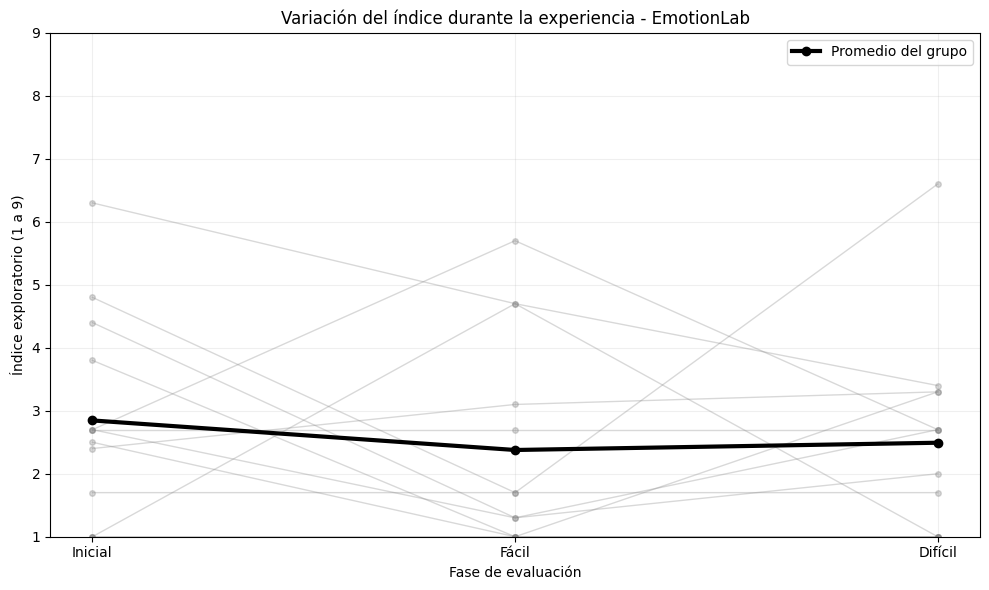

Estudiantes representados: 13
Visualización exploratoria completada.


In [86]:

# =========================================================
# 4.6.3 - VISUALIZACIÓN DEL ÍNDICE POR FASE
# =========================================================

# Generamos el gráfico solamente cuando existan
# estudiantes con los tres índices calculados.

if estudiantes_evaluables.empty:

    print("GRÁFICO PENDIENTE - EMOTIONLAB")
    print("No existen tres índices válidos por estudiante.")
    print("Primero debemos completar las verificaciones del 4.4.")

else:

    # Creamos el espacio donde mostraremos el gráfico.

    fig, ax = plt.subplots(figsize=(10, 6))

    # Convertimos los índices a una matriz numérica.
    #
    # Cada fila representa un estudiante.
    # Cada columna representa una fase.
    #
    # Al transponerla (.T), Matplotlib puede dibujar
    # una línea por estudiante sin utilizar un ciclo for.

    trayectorias = estudiantes_evaluables[
        columnas_indices
    ].to_numpy(dtype=float)

    # Representamos las trayectorias individuales.
    #
    # El gris permite mostrar las diferencias entre
    # estudiantes sin destacar a uno en particular.

    ax.plot(
        range(3),
        trayectorias.T,
        marker="o",
        markersize=4,
        color="gray",
        alpha=0.3,
        linewidth=1
    )

    # Calculamos el promedio de las tres fases
    # para los mismos estudiantes seleccionados.

    promedios = trayectorias.mean(axis=0)

    # Destacamos el promedio general en negro.

    ax.plot(
        range(3),
        promedios,
        marker="o",
        color="black",
        linewidth=3,
        label="Promedio del grupo"
    )

    # Configuramos las etiquetas y la escala.

    ax.set_xticks(range(3), etapas)
    ax.set_ylim(ESCALA_MINIMA, ESCALA_MAXIMA)
    ax.set_yticks(
        range(ESCALA_MINIMA, ESCALA_MAXIMA + 1)
    )

    ax.set_title(
        "Variación del índice durante la experiencia - EmotionLab"
    )

    ax.set_xlabel("Fase de evaluación")
    ax.set_ylabel("Índice exploratorio (1 a 9)")

    # Agregamos una cuadrícula ligera y la leyenda
    # para facilitar la interpretación visual.

    ax.grid(alpha=0.2)
    ax.legend()

    plt.tight_layout()
    plt.show()

    print("Estudiantes representados:", len(estudiantes_evaluables))
    print("Visualización exploratoria completada.")


## **4.7 — Análisis de sensibilidad del índice de tensión**

**¿Qué realizaremos en esta sección?**

En esta sección evaluaremos qué tan sensibles son los resultados del índice exploratorio de tensión percibida de EmotionLab frente a cambios en las ponderaciones utilizadas.

Actualmente, nuestro índice considera un 70 % de nerviosismo y un 30 % de estado emocional. Sin embargo, estas ponderaciones son experimentales, por lo que necesitamos comprobar cuánto influyen en las puntuaciones obtenidas.

**1. Configuraciones que compararemos**

Analizaremos tres escenarios utilizando las mismas respuestas de los estudiantes:

60 % / 40 %: mayor participación del estado emocional.

70 % / 30 %: configuración principal de EmotionLab.

80 % / 20 %: mayor participación del nerviosismo.

**2. Comparación de resultados**

Para cada configuración realizaremos los siguientes cálculos:

Índice por fase: calcularemos las puntuaciones de las evaluaciones inicial, fácil y difícil.

Índice global: obtendremos el promedio de las tres fases.

Diferencias: compararemos cada resultado alternativo con la configuración principal.

Sensibilidad: identificaremos el cambio absoluto promedio y la mayor diferencia registrada.

**3. ¿Por qué es importante?**

Este análisis nos permitirá identificar si los resultados son relativamente estables o si cambian considerablemente cuando modificamos las ponderaciones.

Si pequeñas variaciones en los porcentajes producen grandes diferencias, significaría que el índice depende significativamente de las decisiones experimentales que tomamos.

**4. Consideraciones metodológicas**

Trabajaremos con los 13 estudiantes evaluables, utilizando únicamente respuestas reales completas.

Mantendremos la orientación confirmada de la escala: valores mayores representan mayor tensión percibida.

No modificaremos los datos originales ni realizaremos estimaciones.

No asignaremos categorías de tensión hasta establecer y evaluar sus umbrales.

El análisis de sensibilidad no demuestra que una ponderación sea psicológicamente más válida que otra.

In [89]:

# =========================================================
# 4.7.1 - PREPARACIÓN DEL ANÁLISIS DE SENSIBILIDAD
# =========================================================

# Antes de comparar ponderaciones, comprobamos que
# la orientación emocional haya sido confirmada
# y que el índice principal ya esté calculado.

if ORIENTACION_ESTADO_VALIDADA is not True:
    raise ValueError("Primero debemos validar la escala emocional.")

if type(INVERTIR_ESTADO) is not bool:
    raise ValueError("La inversión de la escala no está definida.")

# Seleccionamos únicamente estudiantes con las tres
# fases completas, sin utilizar valores estimados.

evaluables = resultados_tension["apto_indice_global"]

sensibilidad = resultados_tension.loc[
    evaluables, variables_indice
].copy()

# Guardamos el índice global original del 70/30
# para comprobar posteriormente los nuevos cálculos.

indice_referencia = resultados_tension.loc[
    evaluables, "indice_global"
]

if sensibilidad.empty or indice_referencia.isna().any():
    raise ValueError("No existen índices completos para comparar.")

if sensibilidad.isna().any().any():
    raise ValueError("Hay respuestas faltantes en los evaluables.")

print("Estudiantes seleccionados:", len(sensibilidad))


Estudiantes seleccionados: 13


In [91]:

# =========================================================
# 4.7.2 - CÁLCULO DE LOS ÍNDICES ALTERNATIVOS
# =========================================================

# Confirmamos que la orientación emocional esté validada
# antes de calcular índices con nuevas ponderaciones.

if ORIENTACION_ESTADO_VALIDADA is not True:
    raise ValueError("La orientación emocional no está validada.")

# Esta función aplica las ponderaciones a cada fase
# y devuelve el promedio de las tres evaluaciones.

def calcular_indice_alternativo(datos, peso_nerviosismo):

    if not np.isfinite(peso_nerviosismo) or not 0 <= peso_nerviosismo <= 1:
        raise ValueError("La ponderación debe estar entre 0 y 1.")

    peso_estado = 1 - peso_nerviosismo
    indices = []

    for nerviosismo, estado in indicadores_por_etapa.values():

        estado_ajustado = datos[estado]

        # Invertimos la escala únicamente si la
        # configuración previamente validada lo requiere.

        if INVERTIR_ESTADO:
            estado_ajustado = (
                ESCALA_MINIMA + ESCALA_MAXIMA - estado_ajustado
            )

        # Calculamos el índice de esta fase.

        indice = (
            datos[nerviosismo] * peso_nerviosismo
            + estado_ajustado * peso_estado
        )

        indices.append(indice)

    # Obtenemos el promedio de las tres fases.
    # Cada índice debe estar disponible.

    return pd.concat(indices, axis=1).mean(
        axis=1, skipna=False
    )


# Definimos las tres ponderaciones experimentales.

escenarios = {
    "60_40": 0.60,
    "70_30": 0.70,
    "80_20": 0.80
}

# Creamos las columnas correspondientes a cada escenario.
#
# IMPORTANTE:
# Escribimos indice_ sin una barra invertida.
# Los nombres deben ser exactamente iguales
# a los utilizados en las siguientes celdas.

for nombre, peso in escenarios.items():

    sensibilidad[f"indice_{nombre}"] = (
        calcular_indice_alternativo(sensibilidad, peso)
    )

# Comprobamos que las tres columnas se hayan creado.

columnas_esperadas = [
    "indice_60_40",
    "indice_70_30",
    "indice_80_20"
]

faltantes = [
    columna for columna in columnas_esperadas
    if columna not in sensibilidad.columns
]

if faltantes:
    raise ValueError(f"No se crearon estas columnas: {faltantes}")

print("Índices alternativos calculados correctamente.")

print("\nColumnas generadas:")
print(columnas_esperadas)

print("\nVista de los resultados:")
display(sensibilidad[columnas_esperadas].head().round(2))


Índices alternativos calculados correctamente.

Columnas generadas:
['indice_60_40', 'indice_70_30', 'indice_80_20']

Vista de los resultados:


,indice_60_40,indice_70_30,indice_80_20
0,2.80,2.93,3.07
1,2.60,2.70,2.80
2,1.80,1.77,1.73
3,2.53,2.57,2.60
4,3.60,3.70,3.80


In [92]:

# =========================================================
# 4.7.3 - COMPARACIÓN ENTRE PONDERACIONES
# =========================================================

# El escenario 70/30 debe reproducir el índice global
# calculado en la Etapa 4.5.
#
# np.allclose() compara números decimales considerando
# las pequeñas diferencias de precisión matemática.

if not np.allclose(
    sensibilidad["indice_70_30"],
    indice_referencia,
    rtol=0,
    atol=1e-10
):
    raise ValueError(
        "El escenario 70/30 no coincide con el índice original."
    )

# Calculamos las diferencias respecto del 70/30.
#
# Resultado positivo: el índice alternativo aumentó.
# Resultado negativo: el índice alternativo disminuyó.
# Resultado cero: no hubo cambios.

for escenario in ["60_40", "80_20"]:

    sensibilidad[f"diferencia_{escenario}"] = (
        sensibilidad[f"indice_{escenario}"]
        - sensibilidad["indice_70_30"]
    )

# Comprobamos que todos los índices alternativos
# permanezcan dentro de la escala de EmotionLab.

columnas_escenarios = [
    f"indice_{nombre}" for nombre in escenarios
]

indices_alternativos = sensibilidad[columnas_escenarios]

if not (
    np.isfinite(indices_alternativos.to_numpy()).all()
    and indices_alternativos.ge(ESCALA_MINIMA).all().all()
    and indices_alternativos.le(ESCALA_MAXIMA).all().all()
):
    raise ValueError("Se encontraron índices alternativos inválidos.")

print("Comparación de escenarios verificada correctamente.")
print("El escenario 70/30 reproduce el índice principal.")


Comparación de escenarios verificada correctamente.
El escenario 70/30 reproduce el índice principal.


In [94]:

# =========================================================
# 4.7.4 - RESULTADOS DEL ANÁLISIS DE SENSIBILIDAD
# =========================================================

# Seleccionamos los índices y sus diferencias.
# Mostraremos identificadores temporales para
# no exponer los originales durante la presentación.

columnas_resultado = [
    "indice_60_40",
    "indice_70_30",
    "indice_80_20",
    "diferencia_60_40",
    "diferencia_80_20"
]

vista_sensibilidad = sensibilidad[columnas_resultado].round(2).copy()

# Recuperamos la posición de cada registro dentro
# del conjunto original de estudiantes reales.

posiciones = resultados_tension.index.get_indexer(
    sensibilidad.index
)

vista_sensibilidad.insert(
    0, "Registro",
    [f"Registro {i + 1:02d}" for i in posiciones]
)

print("COMPARACIÓN DE PONDERACIONES - EMOTIONLAB")
display(vista_sensibilidad.reset_index(drop=True))

# Calculamos dos medidas de sensibilidad:
#
# Cambio promedio absoluto:
# cuánto cambia generalmente el índice.
#
# Cambio máximo absoluto:
# la mayor diferencia observada en un estudiante.
#
# abs() evita que aumentos y disminuciones
# se cancelen entre sí.

resumen_sensibilidad = pd.DataFrame([
    {
        "Escenario": escenario.replace("_", "/"),
        "Cambio promedio absoluto": sensibilidad[
            f"diferencia_{escenario}"
        ].abs().mean(),
        "Cambio máximo absoluto": sensibilidad[
            f"diferencia_{escenario}"
        ].abs().max()
    }
    for escenario in ["60_40", "80_20"]
])

print("\nRESUMEN DE SENSIBILIDAD RESPECTO DEL 70/30")
display(resumen_sensibilidad.round(4))


COMPARACIÓN DE PONDERACIONES - EMOTIONLAB


,Registro,indice_60_40,indice_70_30,indice_80_20,diferencia_60_40,diferencia_80_20
0,Registro 01,2.80,2.93,3.07,-0.13,0.13
1,Registro 02,2.60,2.70,2.80,-0.10,0.10
2,Registro 03,1.80,1.77,1.73,0.03,-0.03
3,Registro 04,2.53,2.57,2.60,-0.03,0.03
4,Registro 05,3.60,3.70,3.80,-0.10,0.10
5,Registro 06,1.00,1.00,1.00,0.00,0.00
6,Registro 07,3.00,3.33,3.67,-0.33,0.33
7,Registro 08,2.20,2.23,2.27,-0.03,0.03
8,Registro 09,1.67,1.50,1.33,0.17,-0.17
9,Registro 20,1.80,1.93,2.07,-0.13,0.13



RESUMEN DE SENSIBILIDAD RESPECTO DEL 70/30


,Escenario,Cambio promedio absoluto,Cambio máximo absoluto
0,60/40,0.1051,0.3333
1,80/20,0.1051,0.3333


##**4.8 — Preparación de resultados del índice de tensión**

¿Qué realizaremos en esta sección?

En esta sección organizaremos los resultados del índice exploratorio de tensión percibida de EmotionLab en una tabla que reúna la información principal de cada estudiante.

Para ello, realizaremos tres procesos:

Organización: reuniremos los índices de las fases inicial, fácil y difícil, junto con el índice global.

Identificación: conservaremos los identificadores seudónimos y el estado de evaluación de cada estudiante.

Validación: comprobaremos que los resultados sean consistentes y que no existan clasificaciones asignadas incorrectamente.

1. Información que conservaremos

La tabla incluirá:

Identificador del estudiante: permitirá relacionar cada resultado con su registro.

Respuestas disponibles: indicará cuántos de los seis indicadores necesarios fueron respondidos.

Índices por fase: mostrarán la puntuación calculada para cada momento de la experiencia.

Índice global: representará el promedio de las tres evaluaciones.

Estado de evaluación: distinguirá a los estudiantes evaluables, pendientes de estimación y con datos insuficientes.

Categoría de tensión: quedará pendiente hasta establecer los criterios de clasificación.

2. Disponibilidad de resultados

De acuerdo con los análisis anteriores, contamos con:

13 estudiantes evaluables: tienen un índice global calculado sin estimaciones.

2 estudiantes pendientes de estimación: cuentan con dos fases completas.

12 estudiantes con datos insuficientes: no cumplen los criterios para obtener un índice global.

Los registros incompletos conservarán sus respuestas disponibles sin recibir clasificaciones globales injustificadas.

3. ¿Por qué es importante?

Esta preparación permitirá disponer de los resultados en una estructura consistente, facilitando su utilización en otras partes de EmotionLab.

También nos ayudará a evitar errores como:

Asignar categorías de tensión a estudiantes sin un índice global válido.

Confundir respuestas estimadas con respuestas realmente observadas.

Perder la correspondencia entre los resultados y sus registros originales.

4. Preparación para AWS

Guardaremos la tabla en la variable resultados_heuristicos, que servirá como referencia para futuras visualizaciones y para definir los datos que intercambiará el backend.

Sin embargo, la integración con AWS requerirá implementar y comprobar posteriormente los mecanismos de comunicación, validación y protección de la información.

**En conclusión**, esta preparación permitirá centralizar los índices de tensión percibida y sus estados de evaluación, facilitando su utilización posterior sin alterar las respuestas originales.

In [95]:

# =========================================================
# 4.8.1 - PREPARACIÓN DE RESULTADOS HEURÍSTICOS
# =========================================================

# Reunimos las columnas necesarias para presentar
# los resultados del índice exploratorio de EmotionLab.
#
# Conservamos los índices de las tres fases, el resultado
# global y el estado de disponibilidad de cada estudiante.

columnas_resultado = [
    "id_estudiante",
    "respuestas_para_indice",
    "fases_completas",
    "estado_evaluacion",
    "indice_inicial",
    "indice_facil",
    "indice_dificil",
    "indice_global"
]

# Antes de seleccionar los datos comprobamos que
# todas las columnas estén disponibles.

faltantes = [
    columna for columna in columnas_resultado
    if columna not in resultados_tension.columns
]

if faltantes:
    raise ValueError(f"Faltan columnas: {faltantes}")

# Creamos una copia independiente.
# No modificamos los resultados de las etapas anteriores.

resultados_heuristicos = resultados_tension[
    columnas_resultado
].copy()

# Preparamos la columna destinada a las categorías.
#
# Por ahora todas quedan pendientes porque todavía
# no tenemos umbrales de clasificación validados.
#
# Esto evita conservar categorías antiguas que
# pudieran haberse generado con criterios provisionales.

resultados_heuristicos["categoria_tension"] = pd.NA

print("Tabla de resultados heurísticos preparada.")
print("Registros conservados:", len(resultados_heuristicos))


Tabla de resultados heurísticos preparada.
Registros conservados: 27


In [96]:

# =========================================================
# 4.8.2 - VALIDACIÓN DE RESULTADOS HEURÍSTICOS
# =========================================================

# Confirmamos que la tabla conserva la misma cantidad
# de estudiantes reales que utilizamos en el EDA.

if len(resultados_heuristicos) != len(eda_reales):
    raise ValueError("La cantidad de estudiantes no coincide.")

# Comprobamos que los identificadores sean válidos.
# La conversión temporal a texto permite detectar
# identificadores vacíos o con espacios.

ids = resultados_heuristicos["id_estudiante"].astype("string").str.strip()

if ids.isna().any() or ids.eq("").any() or ids.duplicated().any():
    raise ValueError("Existen identificadores inválidos o duplicados.")

# Solo los estudiantes clasificados como Evaluables
# deben tener un índice global en esta etapa.
#
# Los pendientes de estimación y los registros con
# datos insuficientes conservarán el resultado como NaN.

evaluables = resultados_heuristicos["estado_evaluacion"].eq("Evaluable")
con_indice = resultados_heuristicos["indice_global"].notna()

if not evaluables.equals(con_indice):
    raise ValueError(
        "Los índices globales no coinciden con "
        "los estados de evaluación."
    )

# Verificamos que el índice global corresponda al
# promedio de las tres fases, sin valores estimados.

columnas_indices = [
    "indice_inicial",
    "indice_facil",
    "indice_dificil"
]

promedio_fases = resultados_heuristicos[columnas_indices].mean(
    axis=1, skipna=False
)

if not np.allclose(
    resultados_heuristicos.loc[evaluables, "indice_global"],
    promedio_fases.loc[evaluables],
    rtol=0,
    atol=1e-10
):
    raise ValueError("Existen índices globales inconsistentes.")

# Comprobamos que todos los índices calculados
# estén dentro de la escala definida en EmotionLab.

valores = resultados_heuristicos[
    columnas_indices + ["indice_global"]
].to_numpy(dtype=float)

valores_presentes = valores[~np.isnan(valores)]

if not (
    np.isfinite(valores_presentes).all()
    and ((valores_presentes >= ESCALA_MINIMA)
         & (valores_presentes <= ESCALA_MAXIMA)).all()
):
    raise ValueError("Se encontraron índices fuera de la escala.")

print("Validación de resultados completada correctamente.")
print("Índices globales verificados:", int(con_indice.sum()))
print("Categorías de tensión: pendientes de clasificación.")


Validación de resultados completada correctamente.
Índices globales verificados: 13
Categorías de tensión: pendientes de clasificación.


In [97]:

# =========================================================
# 4.8.3 - PRESENTACIÓN DE RESULTADOS HEURÍSTICOS
# =========================================================

# Creamos una copia para mostrar los resultados.
# Conservamos los identificadores originales en memoria,
# pero utilizamos etiquetas temporales en la presentación.

vista_heuristica = resultados_heuristicos.drop(
    columns="id_estudiante"
).copy()

vista_heuristica.insert(
    0,
    "Registro",
    [f"Registro {i:02d}" for i in range(1, len(vista_heuristica) + 1)]
)

# Redondeamos solo la visualización.
# Los resultados almacenados mantienen su precisión.

print("RESULTADOS HEURÍSTICOS - EMOTIONLAB")
display(vista_heuristica.round(2))

# Agrupamos los estudiantes según su estado.
# reindex() mantiene las tres categorías visibles
# aunque alguna no tenga estudiantes.

resumen_heuristicos = (
    resultados_heuristicos["estado_evaluacion"]
    .value_counts()
    .reindex(
        ["Evaluable", "Pendiente de estimación", "Datos insuficientes"],
        fill_value=0
    )
)

print("\nRESUMEN DE DISPONIBILIDAD")
display(resumen_heuristicos.to_frame(name="Estudiantes"))

# Presentamos las cantidades de resultados disponibles.

print("\nRESUMEN GENERAL")
print("Registros reales:", len(resultados_heuristicos))
print("Índices globales:", resultados_heuristicos["indice_global"].notna().sum())
print("Categorías asignadas:", resultados_heuristicos["categoria_tension"].notna().sum())

print("\nTabla preparada para los siguientes análisis.")


RESULTADOS HEURÍSTICOS - EMOTIONLAB


,Registro,respuestas_para_indice,fases_completas,estado_evaluacion,indice_inicial,indice_facil,indice_dificil,indice_global,categoria_tension
0,Registro 01,6,3,Evaluable,2.4,3.1,3.3,2.93,<NA>
1,Registro 02,6,3,Evaluable,2.7,2.7,2.7,2.70,<NA>
2,Registro 03,6,3,Evaluable,1.0,1.0,3.3,1.77,<NA>
3,Registro 04,6,3,Evaluable,4.4,1.3,2.0,2.57,<NA>
4,Registro 05,6,3,Evaluable,2.7,5.7,2.7,3.70,<NA>
5,Registro 06,6,3,Evaluable,1.0,1.0,1.0,1.00,<NA>
6,Registro 07,6,3,Evaluable,1.7,1.7,6.6,3.33,<NA>
7,Registro 08,6,3,Evaluable,1.0,4.7,1.0,2.23,<NA>
8,Registro 09,6,3,Evaluable,2.5,1.0,1.0,1.50,<NA>
9,Registro 10,4,2,Pendiente de estimación,8.0,8.0,NaN,NaN,<NA>



RESUMEN DE DISPONIBILIDAD


,Estudiantes
estado_evaluacion,
Evaluable,13
Pendiente de estimación,2
Datos insuficientes,12



RESUMEN GENERAL
Registros reales: 27
Índices globales: 13
Categorías asignadas: 0

Tabla preparada para los siguientes análisis.


## Conclusión de la Etapa 4: Índice exploratorio de tensión percibida

Durante esta etapa desarrollamos e implementamos el índice exploratorio de tensión percibida de EmotionLab, con el objetivo de resumir las respuestas de nerviosismo y estado emocional registradas durante las tres fases de la experiencia.

### 1. Construcción del índice

Establecimos una fórmula experimental que combina dos indicadores:

- **Nerviosismo:** ponderación del 70 %.
- **Estado emocional:** ponderación del 30 %.
- **Escala de evaluación:** valores de 1 a 9, donde las puntuaciones mayores representan mayor tensión percibida según la orientación confirmada de los cuestionarios.

Calculamos un índice independiente para las fases inicial, fácil y difícil. Posteriormente, obtuvimos un índice global mediante el promedio de las tres evaluaciones.

### 2. Disponibilidad de información

De los **27 registros reales** recopilados, identificamos:

- **13 estudiantes evaluables:** cuentan con las seis respuestas necesarias y un índice global calculado.
- **2 estudiantes pendientes de estimación:** tienen dos fases completas.
- **12 estudiantes con datos insuficientes:** no cumplen los requisitos para calcular un índice global.

Durante esta etapa conservamos las respuestas originales y no realizamos estimaciones de valores faltantes.

### 3. Resultados de tensión percibida

Al analizar los 13 estudiantes evaluables, obtuvimos los siguientes promedios:

| Fase | Índice promedio |
|---|---:|
| Inicial | 2,85 |
| Fácil | 2,38 |
| Difícil | 2,49 |

Los resultados muestran una disminución del índice promedio durante la fase fácil y un ligero aumento durante la fase difícil.

Sin embargo, las trayectorias individuales evidencian diferencias entre estudiantes, por lo que no todos experimentaron las mismas variaciones.

Estas diferencias tampoco permiten afirmar que la dificultad de las presentaciones haya causado los cambios observados.

### 4. Análisis de sensibilidad

Comparamos tres configuraciones de ponderación: **60/40, 70/30 y 80/20**, utilizando los mismos 13 estudiantes.

Los resultados fueron:

- **Cambio promedio absoluto:** 0,1051 puntos.
- **Cambio máximo absoluto:** 0,3333 puntos.
- **Consistencia:** la configuración 70/30 reprodujo correctamente el índice original.

Estos resultados sugieren que las puntuaciones presentan una sensibilidad numérica relativamente baja frente a las modificaciones de ponderación evaluadas.

No obstante, esta estabilidad matemática no demuestra la validez psicológica de la fórmula.

### 5. Limitaciones y funcionalidades pendientes

Aunque logramos implementar el cálculo del índice, todavía existen aspectos que debemos considerar:

- **Ponderaciones experimentales:** los porcentajes utilizados no provienen de una escala psicológica validada.
- **Muestra limitada:** solamente 13 estudiantes cuentan con un índice global calculado.
- **Estimaciones pendientes:** todavía debemos evaluar cómo tratar los casos con dos fases completas.
- **Categorías de tensión:** aún no hemos establecido umbrales suficientemente justificados para clasificar los resultados en calma, tensión moderada o tensión elevada.

Es importante destacar que el índice representa una interpretación experimental de respuestas autodeclaradas y **no constituye un diagnóstico clínico de estrés**.

### 6. Resultado final y próxima etapa

La Etapa 4 permitió desarrollar un procedimiento funcional para calcular índices de tensión por fase y un resultado global, además de generar visualizaciones, comprobar la consistencia de los cálculos y analizar su sensibilidad.

También organizamos los resultados en la variable `resultados_heuristicos`, conservando los 27 registros reales y diferenciando los índices calculados de aquellos pendientes.

Con estos resultados podremos avanzar hacia la **Etapa 5: Preparación de datos para Machine Learning**, donde seleccionaremos y transformaremos las variables necesarias para aplicar posteriormente algoritmos de agrupamiento no supervisado.

**En conclusión**, logramos construir una herramienta exploratoria que resume las respuestas emocionales de los estudiantes durante una experiencia de EmotionLab, estableciendo una base técnica para los análisis posteriores y manteniendo claramente diferenciados los indicadores experimentales de las agrupaciones obtenidas mediante Machine Learning.